## Test Simple Sampling - sampler

In [1]:
%load_ext autoreload
%autoreload 1

import os
os.environ["QUANTDATA_ROOT"] = "/mnt/c/Users/Public/quantdata"

from cdxcore.verbose import Context
verbose = Context("all")
with verbose.write_t("Importing torch...", end='') as tme:   
    import torch
    verbose.write(f"done; this took {tme}.", head=False)

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.torch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler

from quantdata.dysanos.simple.sampler import SimpleSampler, SimpleConfig, SamplingConfig, ExpiryFilter, RawDayFilter, SampleDaysConfig, DateRange, PoolConfig
from cdxcore.verbose import Context
from datetime import date

def test():
    simple_config = SimpleConfig(
            tickers = ['SPX','NDX','RUT'],
            date_range = DateRange(start=date(2015, 1, 1), end=date(2025, 7, 1)),
            raw_day_filter = RawDayFilter(),
            expiry_filter = ExpiryFilter(),
            sample_days_config = SampleDaysConfig(),
            sampling_config = SamplingConfig(num_samples=20)
    )
    pool_config = PoolConfig(num_workers=4, threading=False) # no parallel processing for testing
    verbose = Context.all
    refresh_cache = False

    sampler = SimpleSampler(simple_config=simple_config, pool_config=pool_config, refresh_cache=refresh_cache, verbose=verbose)
    return sampler

sampler = test()
print("/done")

00: Importing torch...done; this took 12s.
00: Generating samples for 3 tickers NDX, RUT and SPX with from 2015-01-01 to 2025-07-01... done; this took 5s.
00: Found the following number of samples per ticker: NDX: 2617, RUT: 2617 and SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker NDX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
01:   Ticker RUT: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 1233 training samples and 309 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 5s.

## Test sampling

In [2]:
"""
Shapes
"""

from prettytable import PrettyTable

def test_shapes():
    shapes = sampler.shapes( 10 )

    tbl = PrettyTable()
    tbl.field_names = ["Ticker", "Shape"]

    for k, v in shapes.items():
        tbl.add_row([k, v])
    
    print(tbl)

test_shapes()   



+-------------------+----------------+
|       Ticker      |     Shape      |
+-------------------+----------------+
|   ask_pure_delta  | (10, 25, 1000) |
|    ask_pure_dk    | (10, 25, 1000) |
|   ask_pure_gamma  | (10, 25, 1000) |
|   ask_pure_price  | (10, 25, 1000) |
|   ask_pure_theta  | (10, 25, 1000) |
|   ask_pure_vega   | (10, 25, 1000) |
|      ask_vol      | (10, 25, 1000) |
|   bid_pure_delta  | (10, 25, 1000) |
|    bid_pure_dk    | (10, 25, 1000) |
|   bid_pure_gamma  | (10, 25, 1000) |
|   bid_pure_price  | (10, 25, 1000) |
|   bid_pure_theta  | (10, 25, 1000) |
|   bid_pure_vega   | (10, 25, 1000) |
|      bid_vol      | (10, 25, 1000) |
|      call_ask     | (10, 25, 1000) |
|      call_bid     | (10, 25, 1000) |
|         df        | (10, 25, 1000) |
|        fwd        | (10, 25, 1000) |
|       is_am       | (10, 25, 1000) |
|    is_american    | (10, 25, 1000) |
|      is_valid     | (10, 25, 1000) |
| log_open_interest | (10, 25, 1000) |
|     log_volume    | (10

In [3]:
from prettytable import PrettyTable
from cdxcore.util import fmt_list, fmt_big_byte_number

def test_batch():
    print("Loading torch...", end='', flush=True)
    import torch as torch
    print("done.")
    g = torch.Generator(device="cpu")
    g.manual_seed(1234)
    batch_ix, batch = sampler(g, trn=True, batch_size=10, device="cpu", return_batch_indices=True)

    # indices
    tbl = PrettyTable()
    tbl.field_names = ["Ticker", "Date"]

    for bix in batch_ix:
        date = sampler.data[bix.ticker].dates[bix.index]
        tbl.add_row([bix.ticker, bix.date])
    print("Samples")
    print(tbl)

    tbl = PrettyTable()
    tbl.field_names = ["Ticker", "Shape", "Type", "Size", "Device"]

    for k, v in batch.items():
        tbl.add_row([k, tuple(v.shape), v.dtype, fmt_big_byte_number(v.nbytes), v.device])
    
    print(tbl)

test_batch()



Loading torch...

done.
Samples
+--------+------------+
| Ticker |    Date    |
+--------+------------+
|  NDX   | 2019-02-26 |
|  RUT   | 2021-12-28 |
|  NDX   | 2018-08-14 |
|  SPX   | 2015-03-30 |
|  RUT   | 2020-10-28 |
|  NDX   | 2017-05-03 |
|  RUT   | 2020-08-25 |
|  NDX   | 2022-10-13 |
|  NDX   | 2021-06-15 |
|  SPX   | 2021-09-23 |
+--------+------------+
+-------------------+----------------+---------------+------------+--------+
|       Ticker      |     Shape      |      Type     |    Size    | Device |
+-------------------+----------------+---------------+------------+--------+
|   ask_pure_delta  | (10, 25, 1000) | torch.float32 |  976.56KB  |  cpu   |
|    ask_pure_dk    | (10, 25, 1000) | torch.float32 |  976.56KB  |  cpu   |
|   ask_pure_gamma  | (10, 25, 1000) | torch.float32 |  976.56KB  |  cpu   |
|   ask_pure_price  | (10, 25, 1000) | torch.float32 |  976.56KB  |  cpu   |
|   ask_pure_theta  | (10, 25, 1000) | torch.float32 |  976.56KB  |  cpu   |
|   ask_pure_vega   | (10, 25, 100

Loading torch...done.


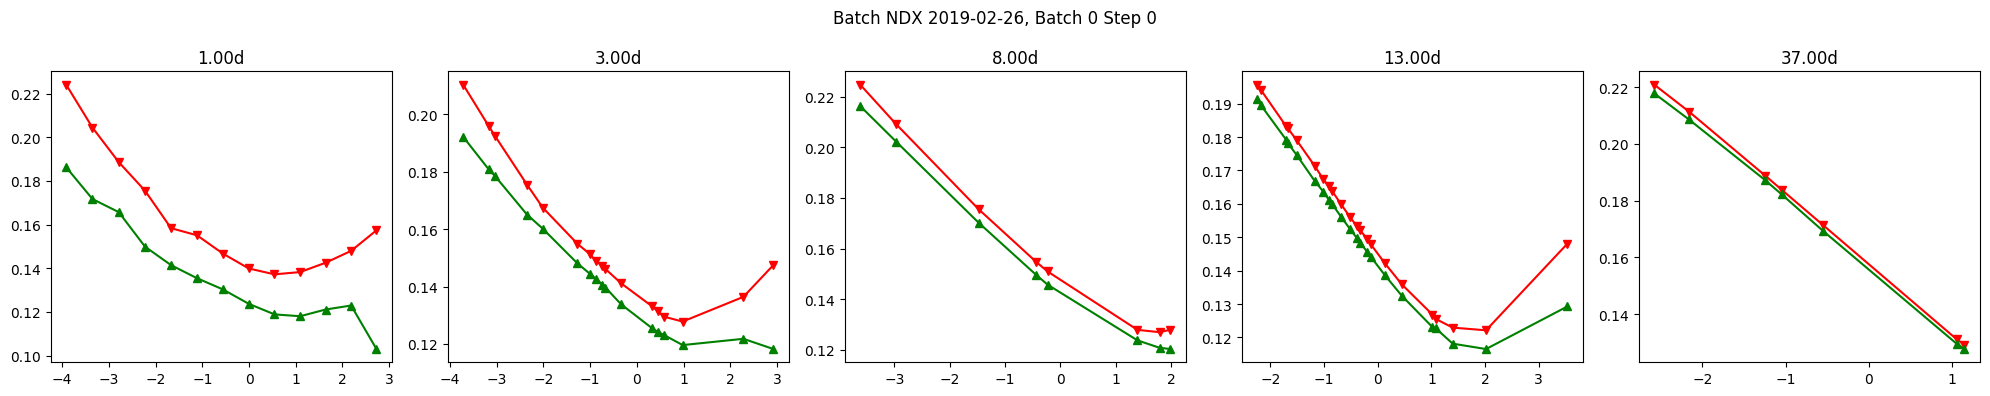

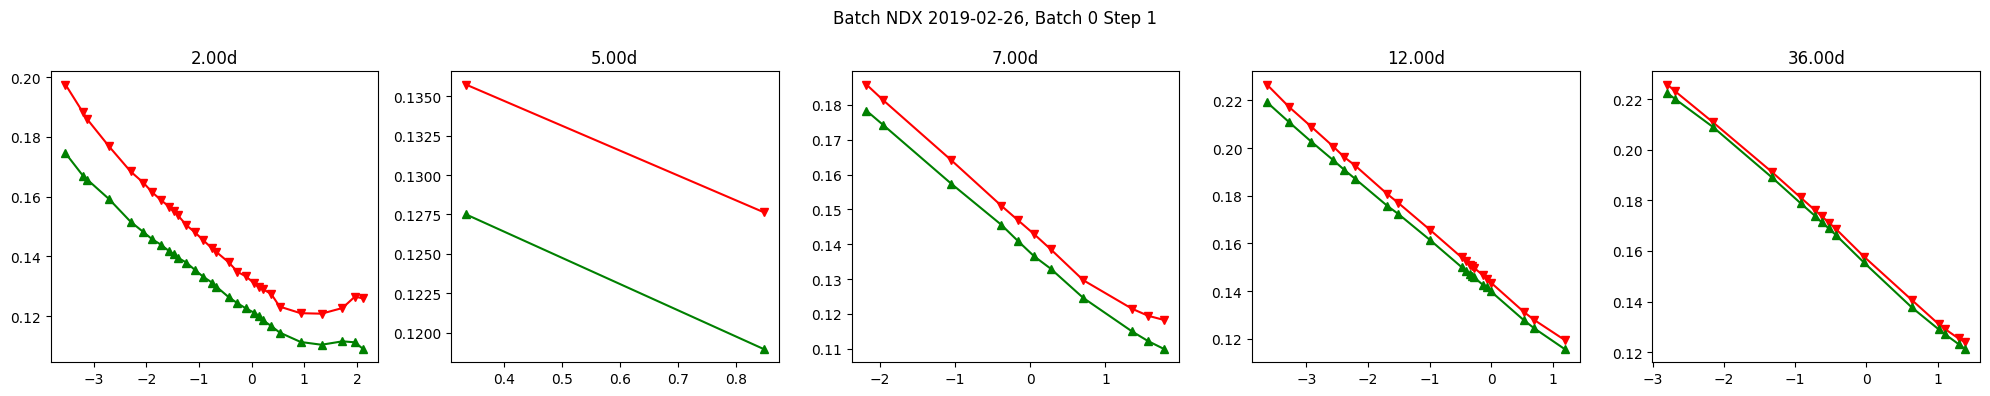

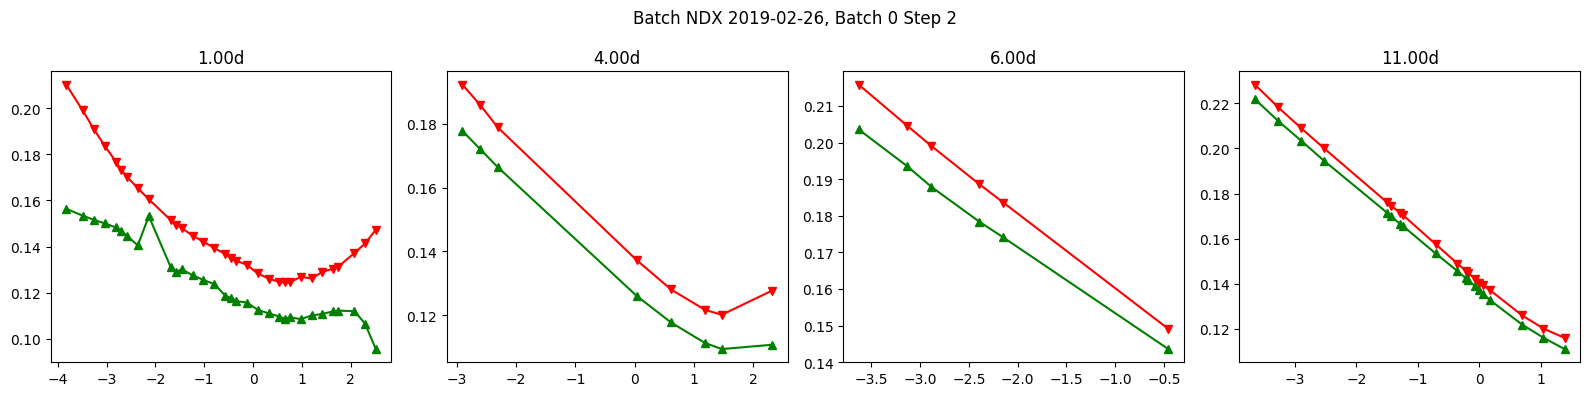

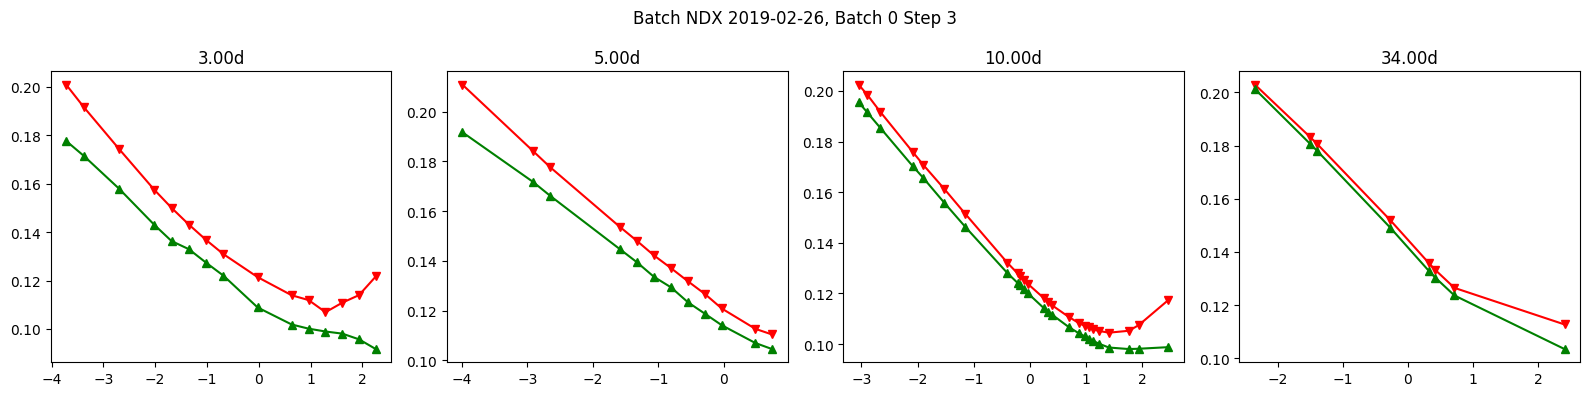

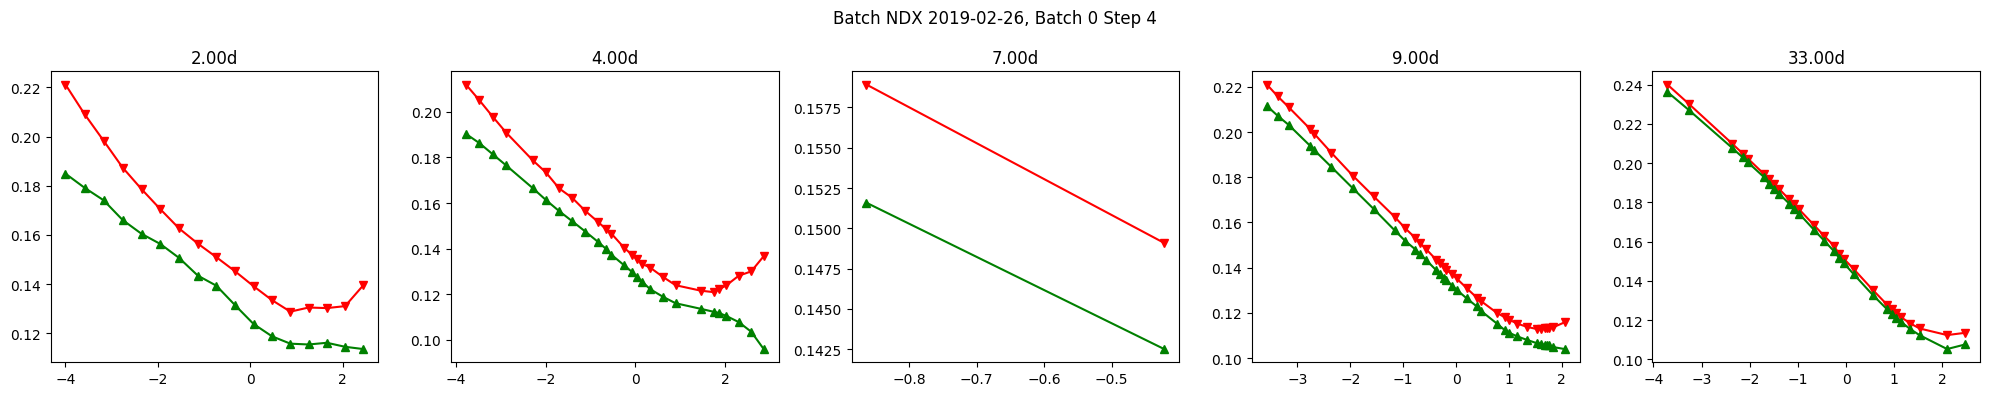

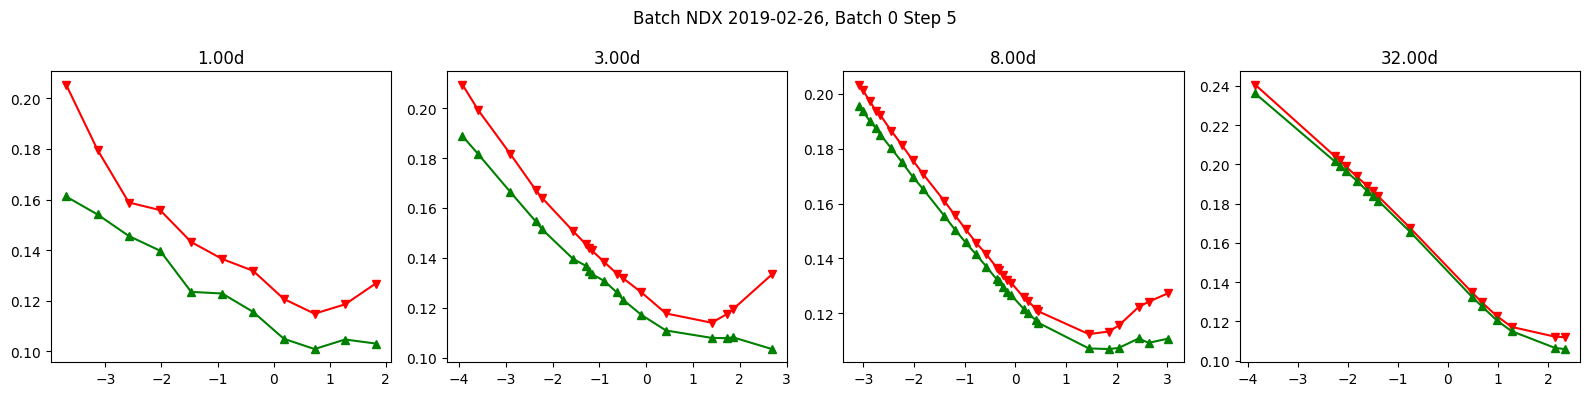

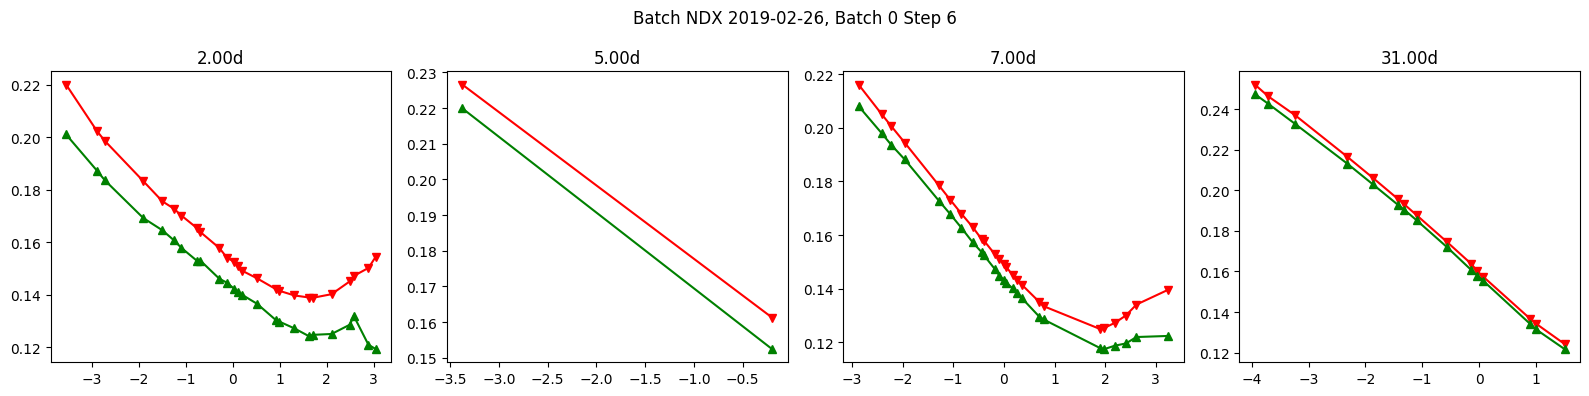

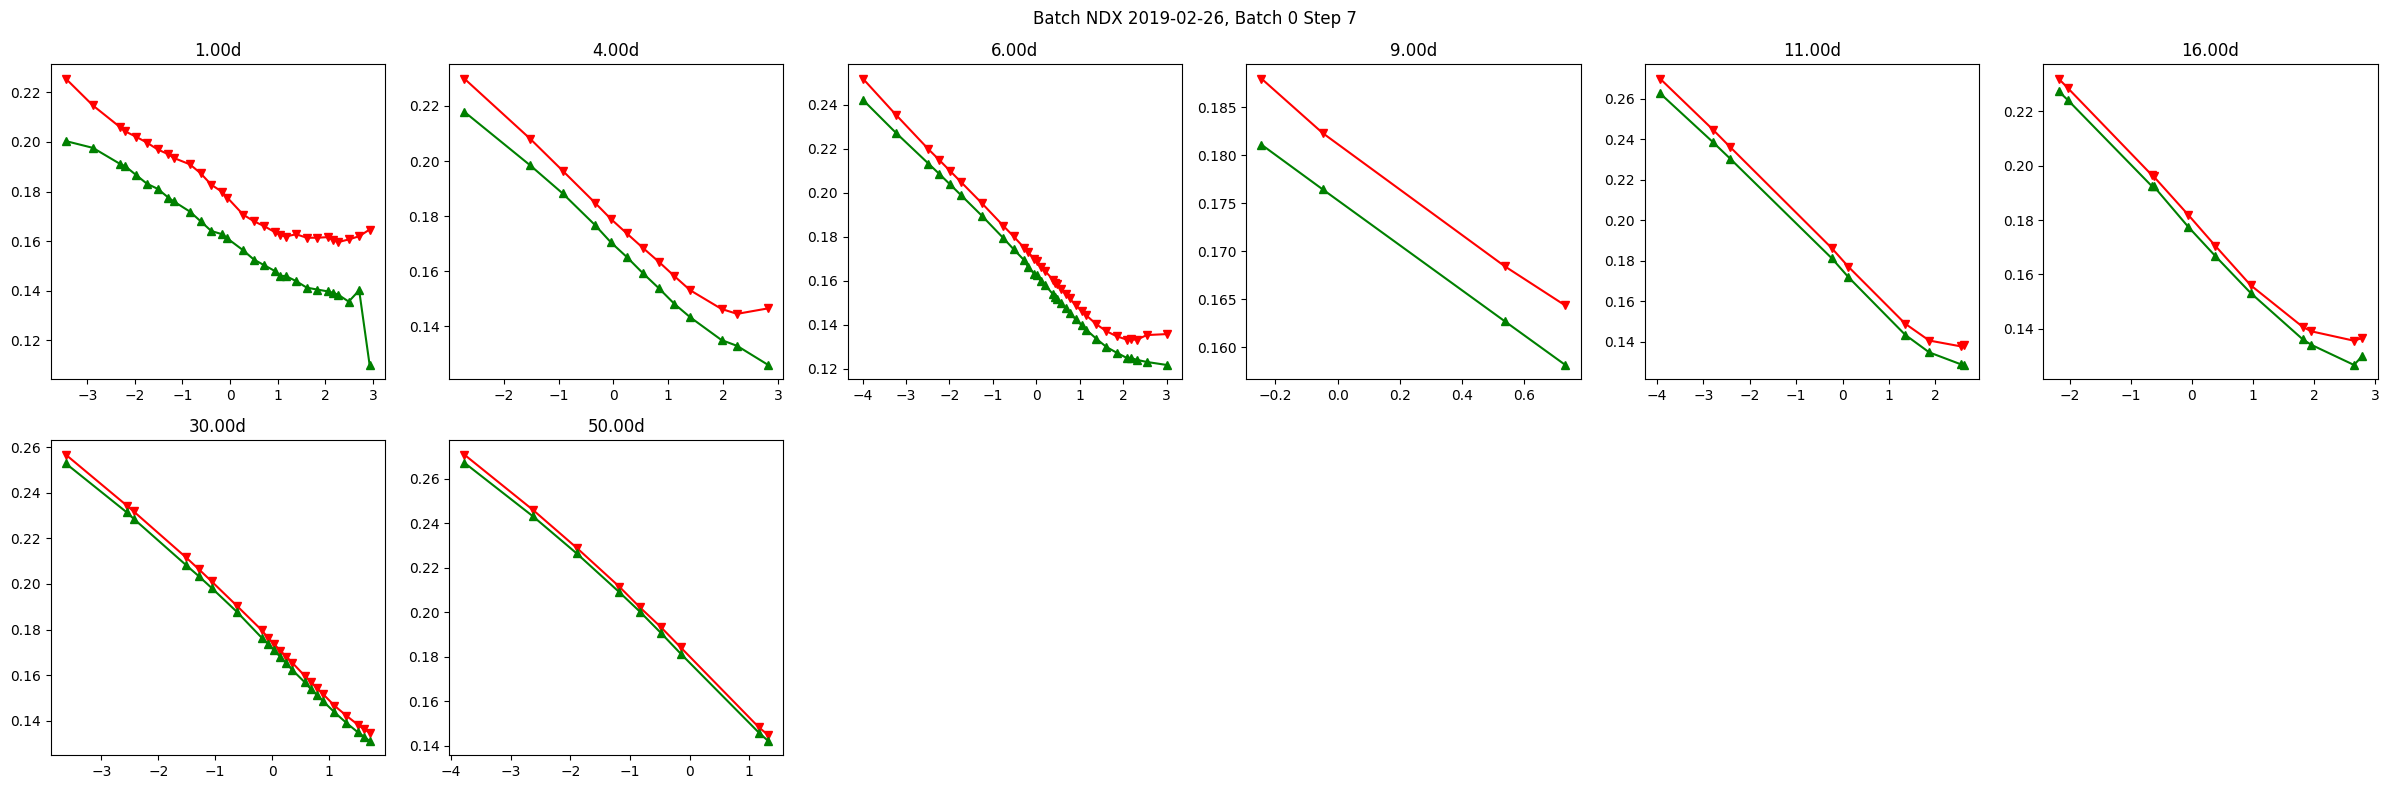

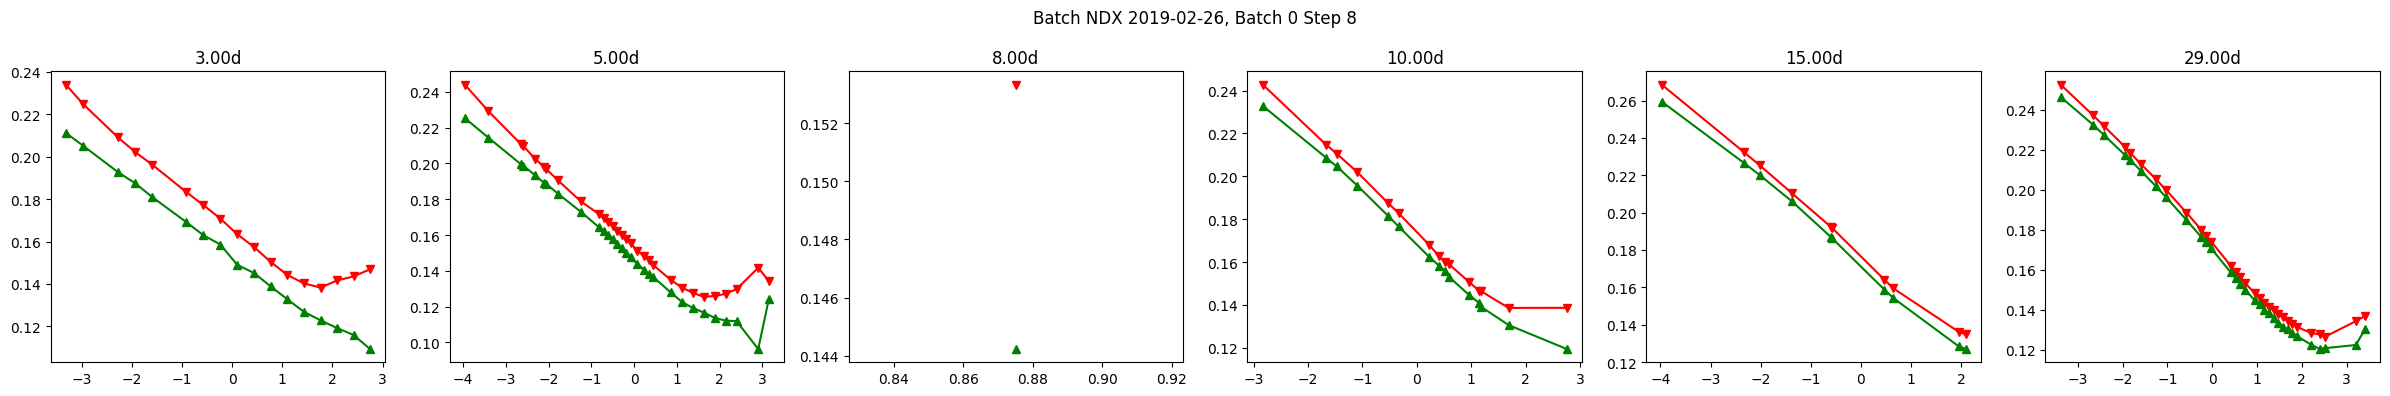

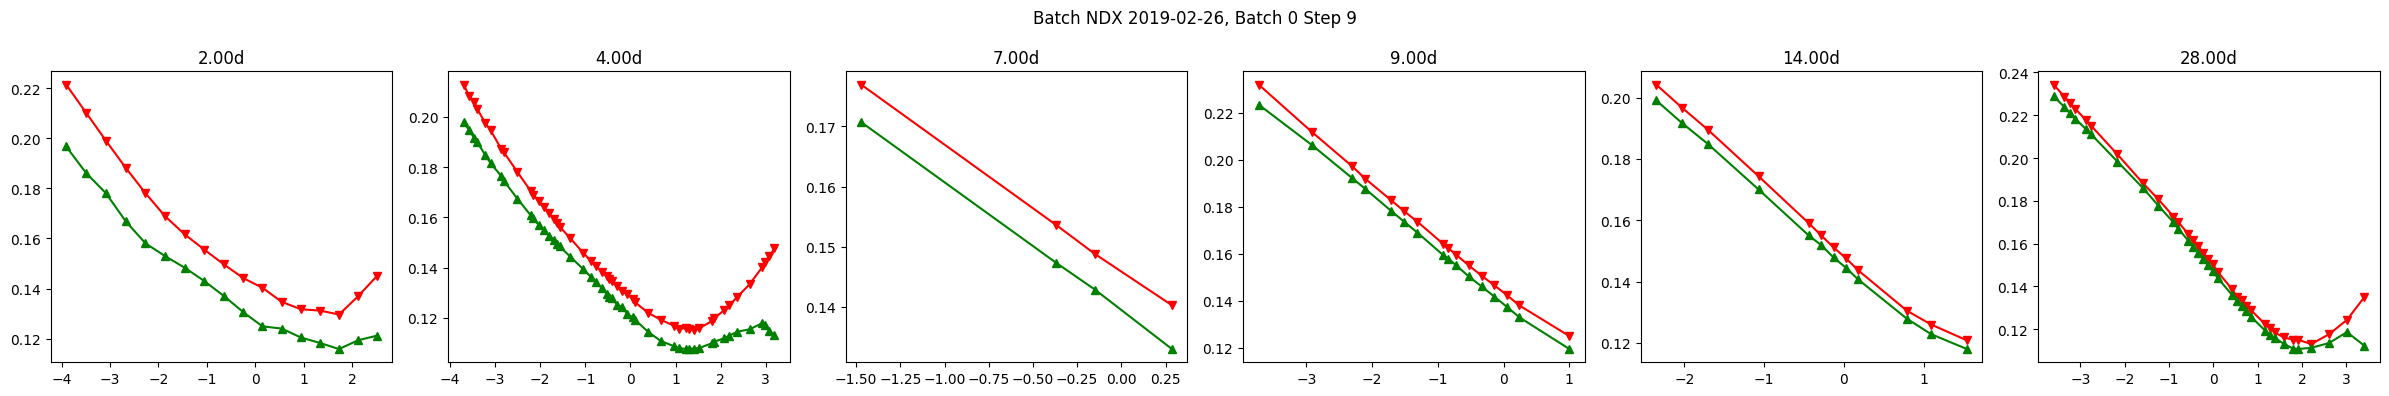

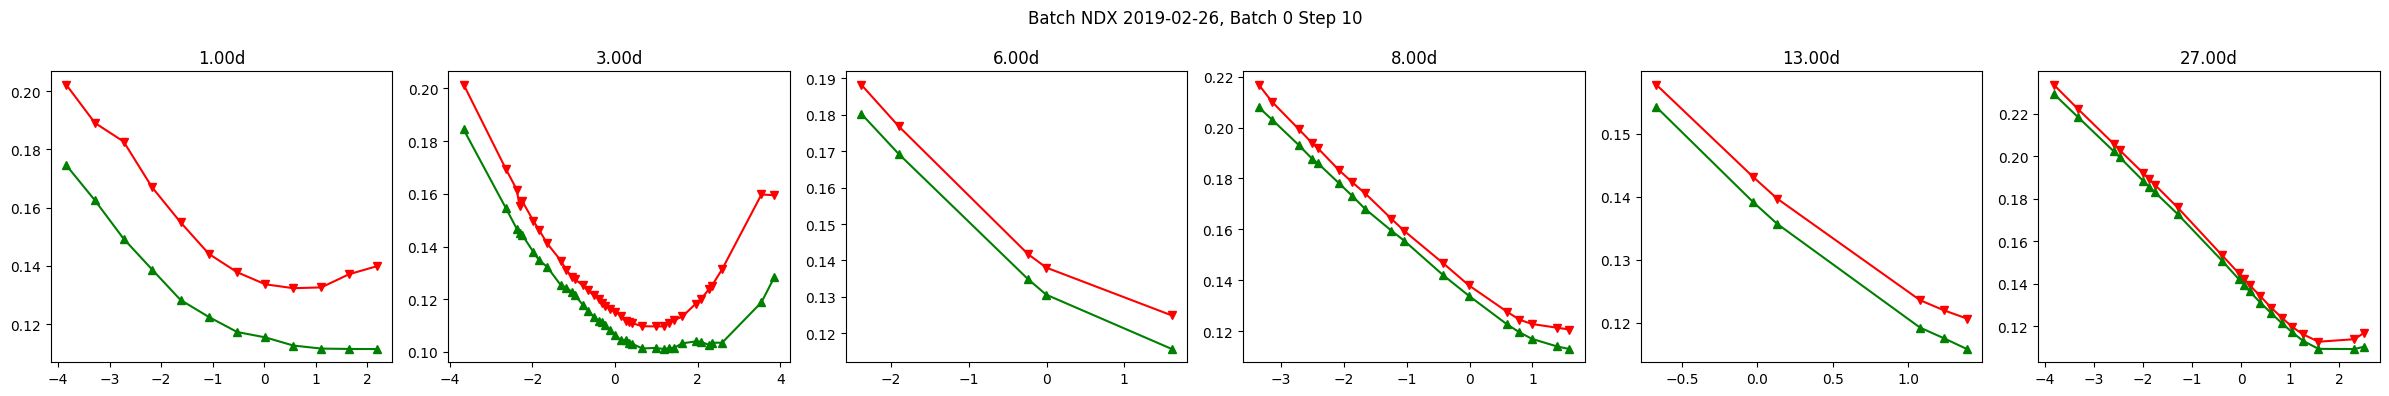

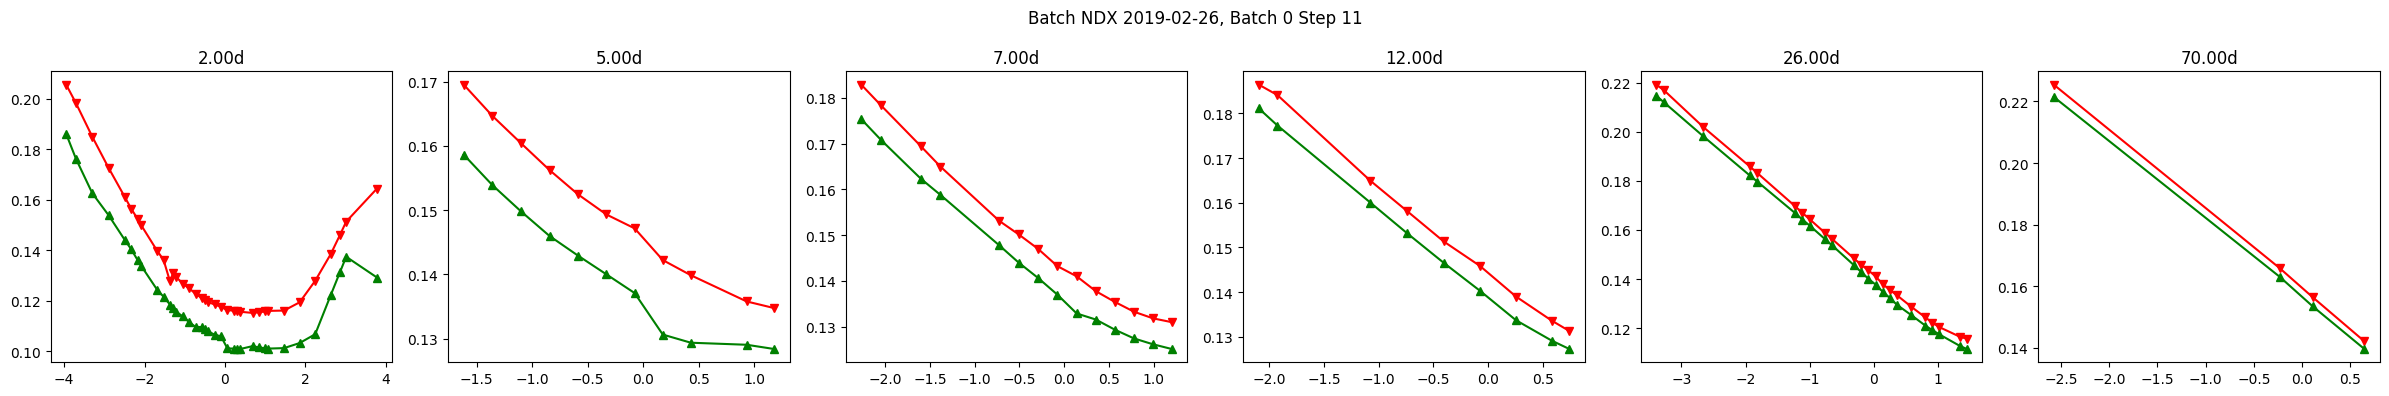

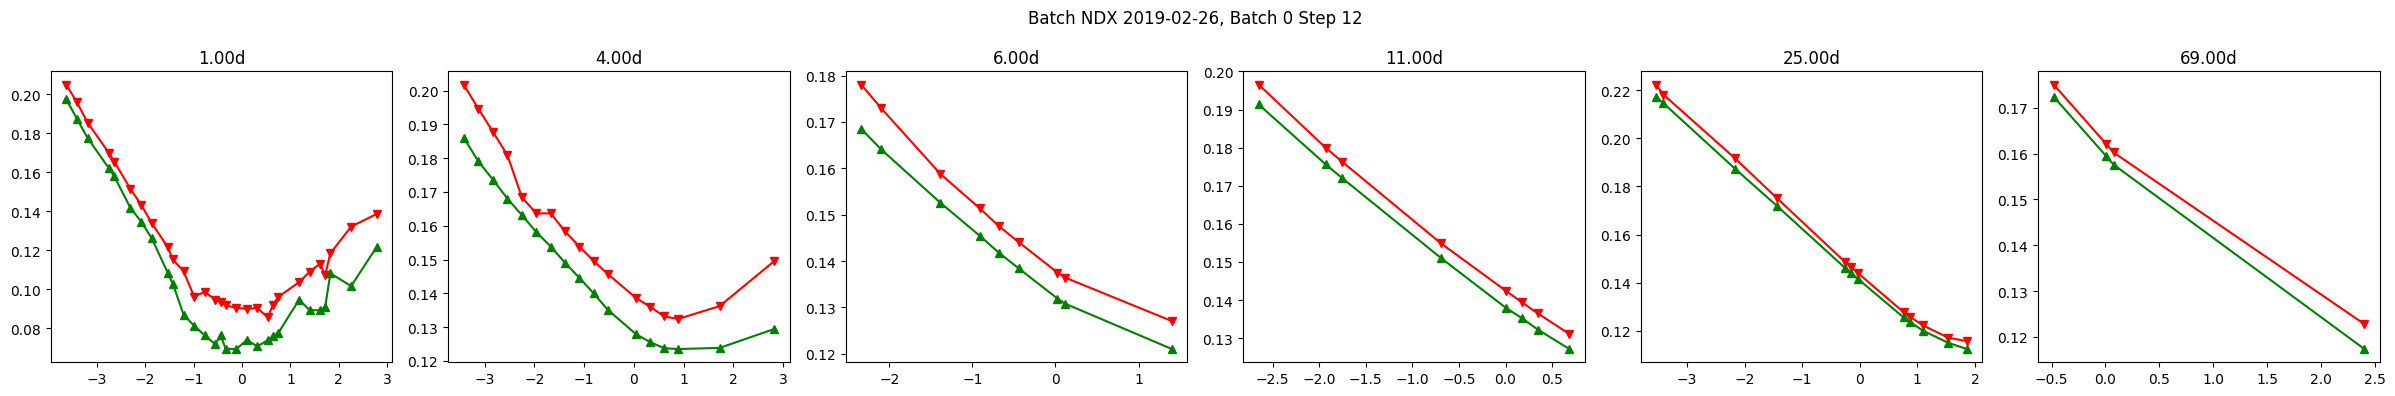

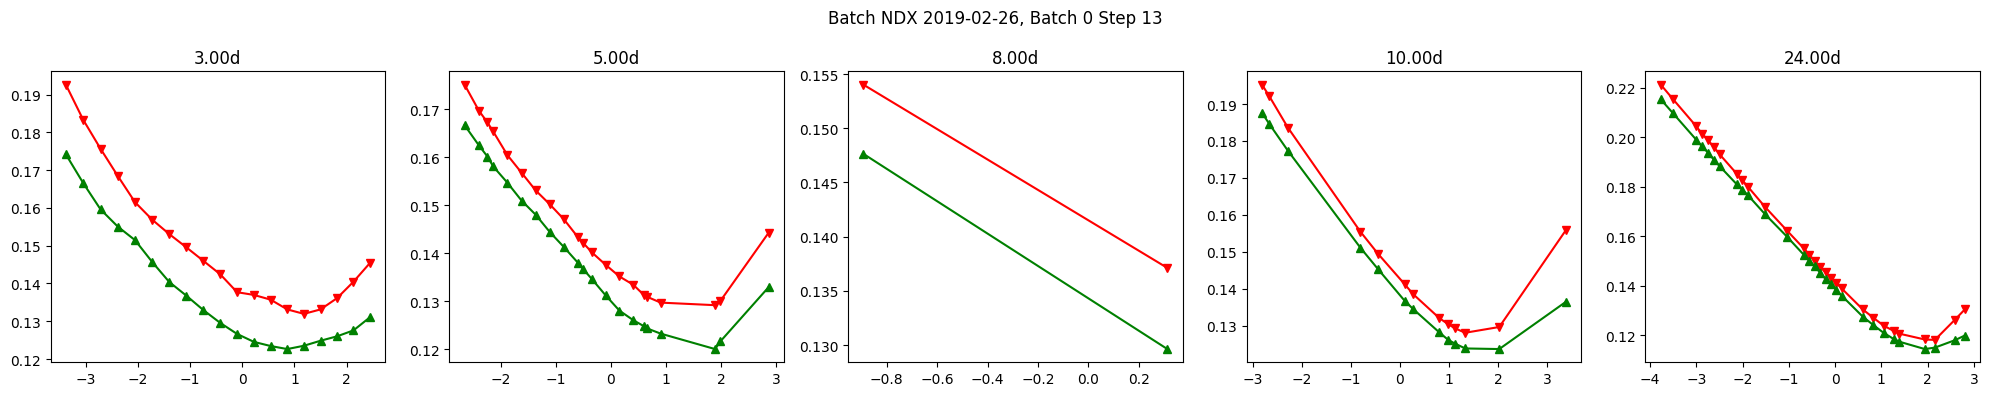

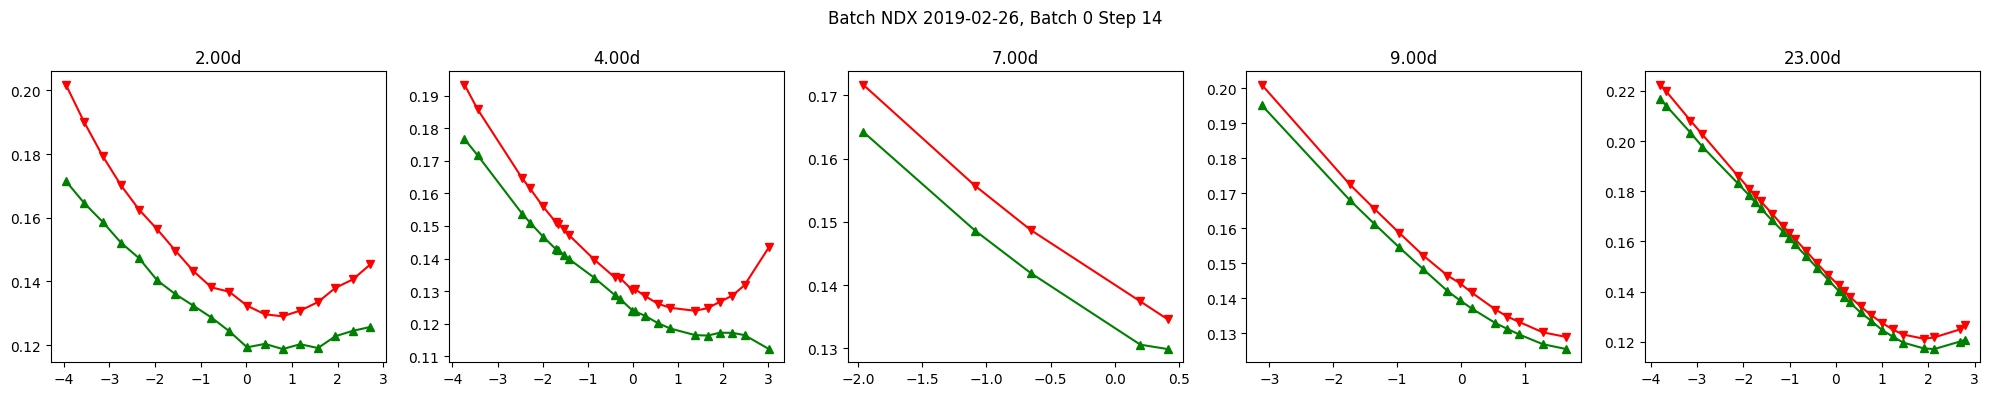

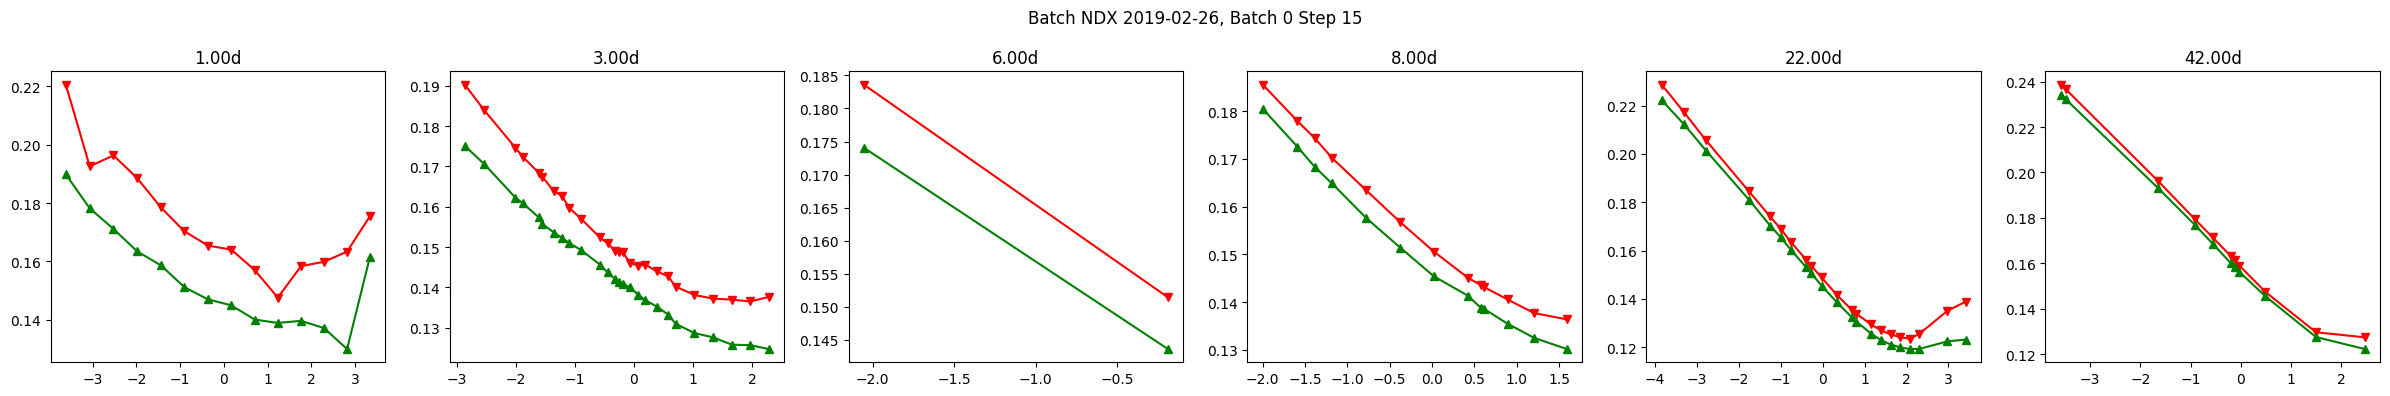

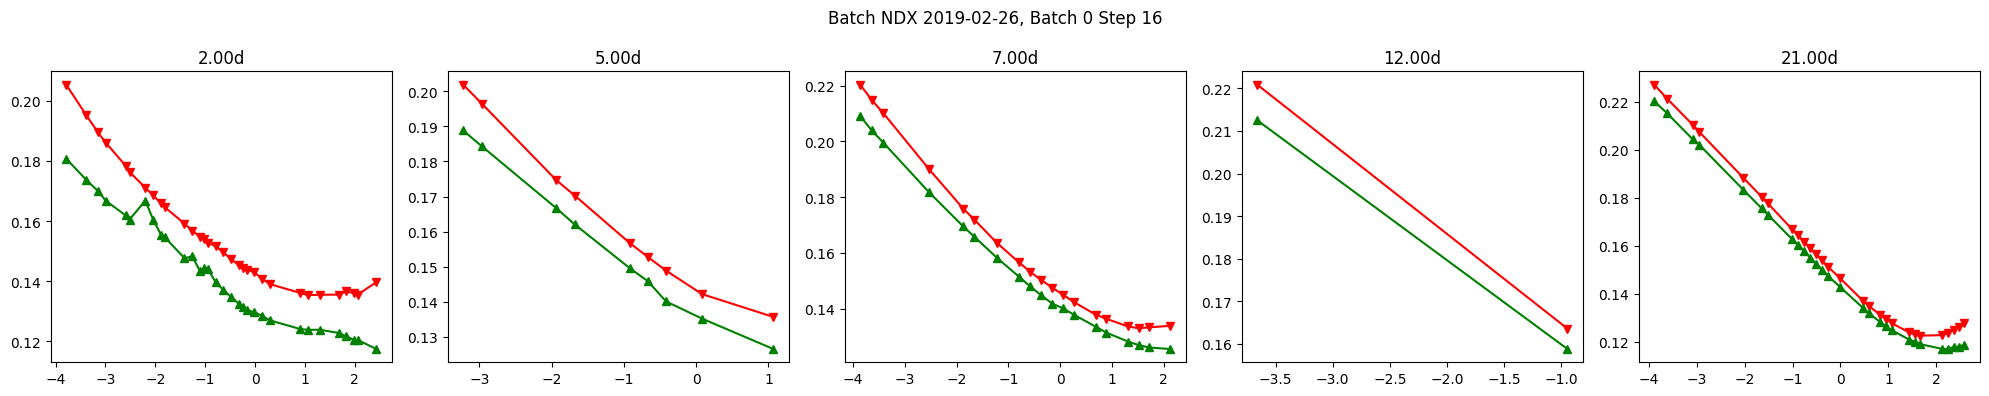

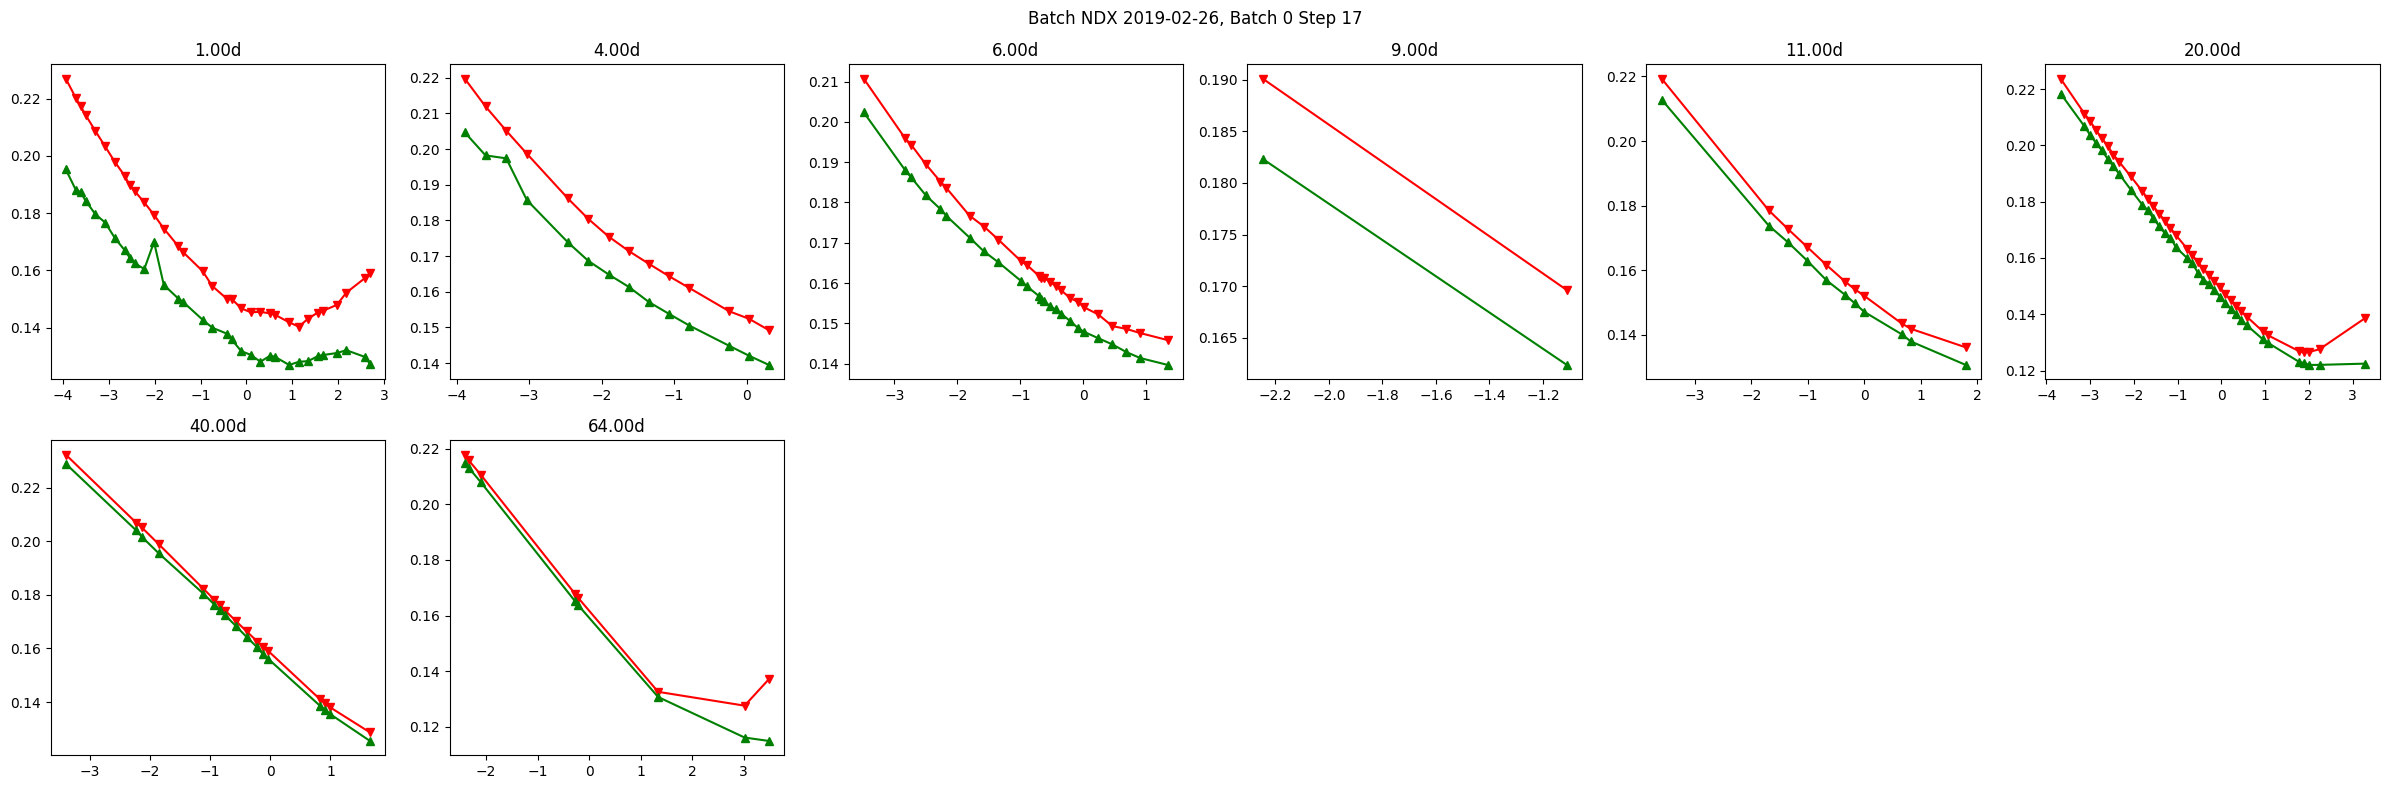

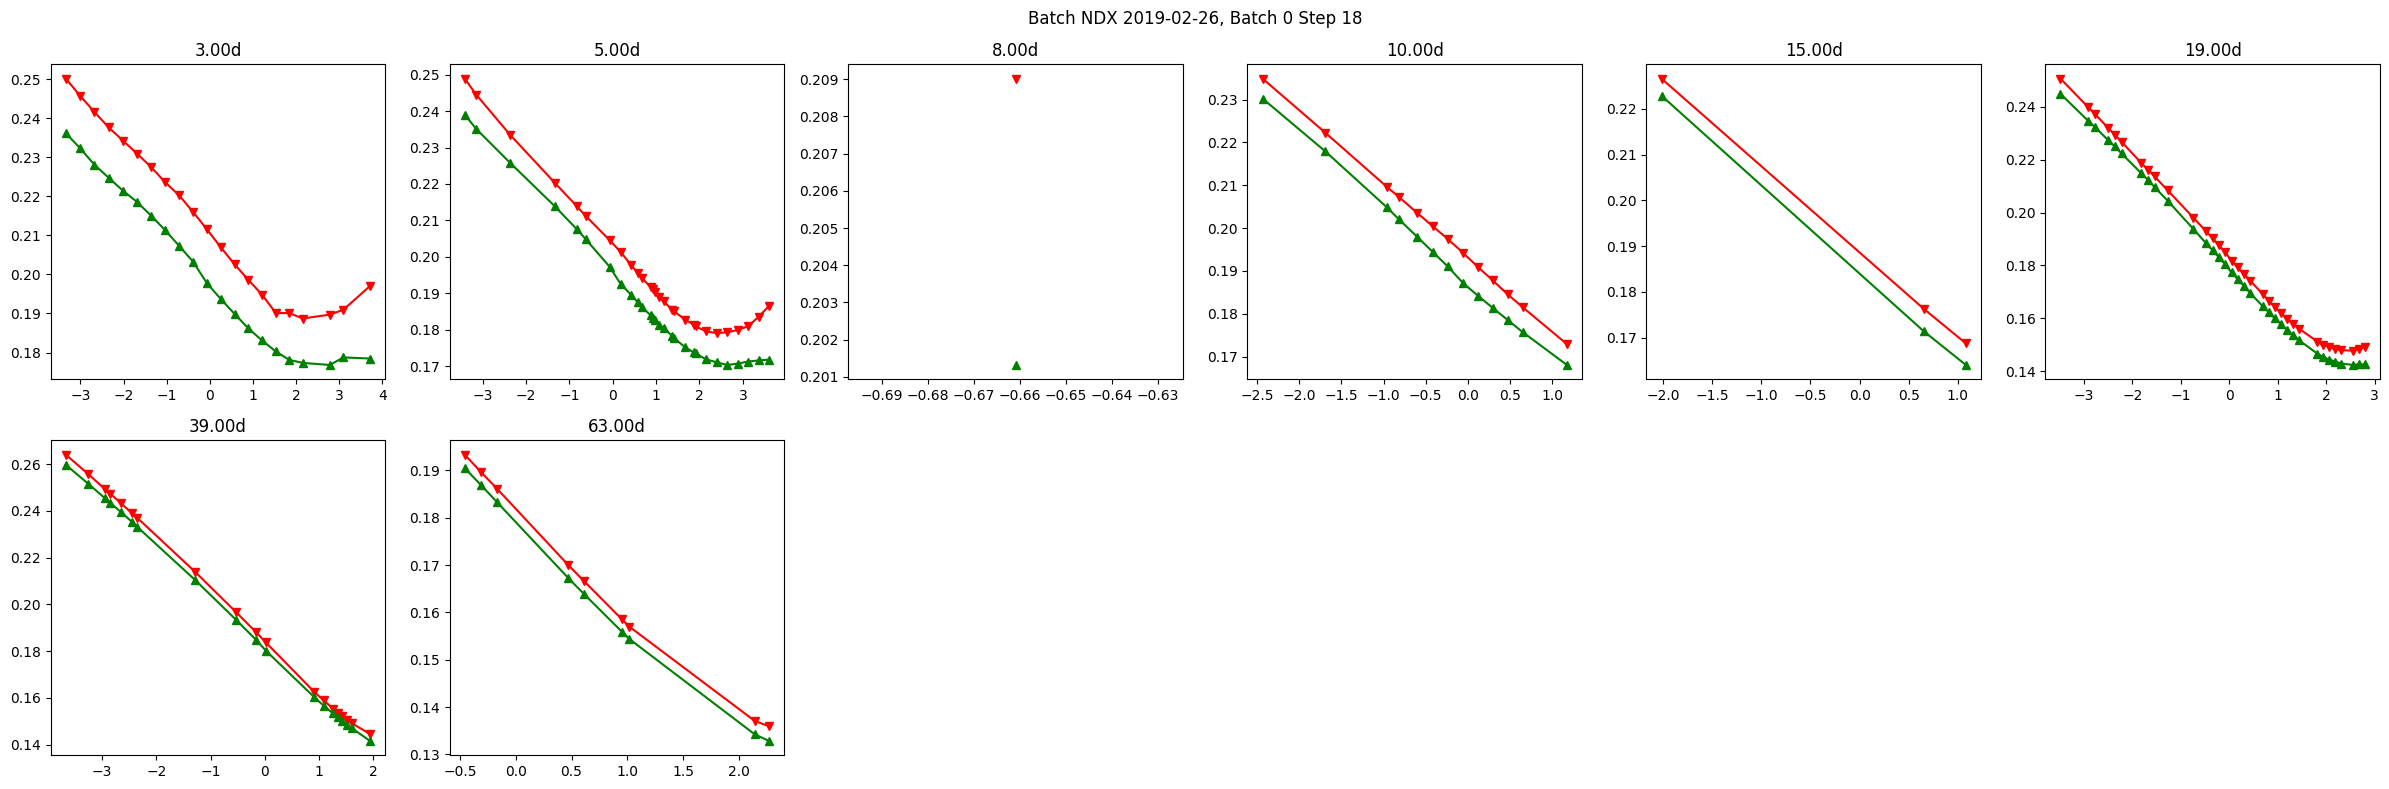

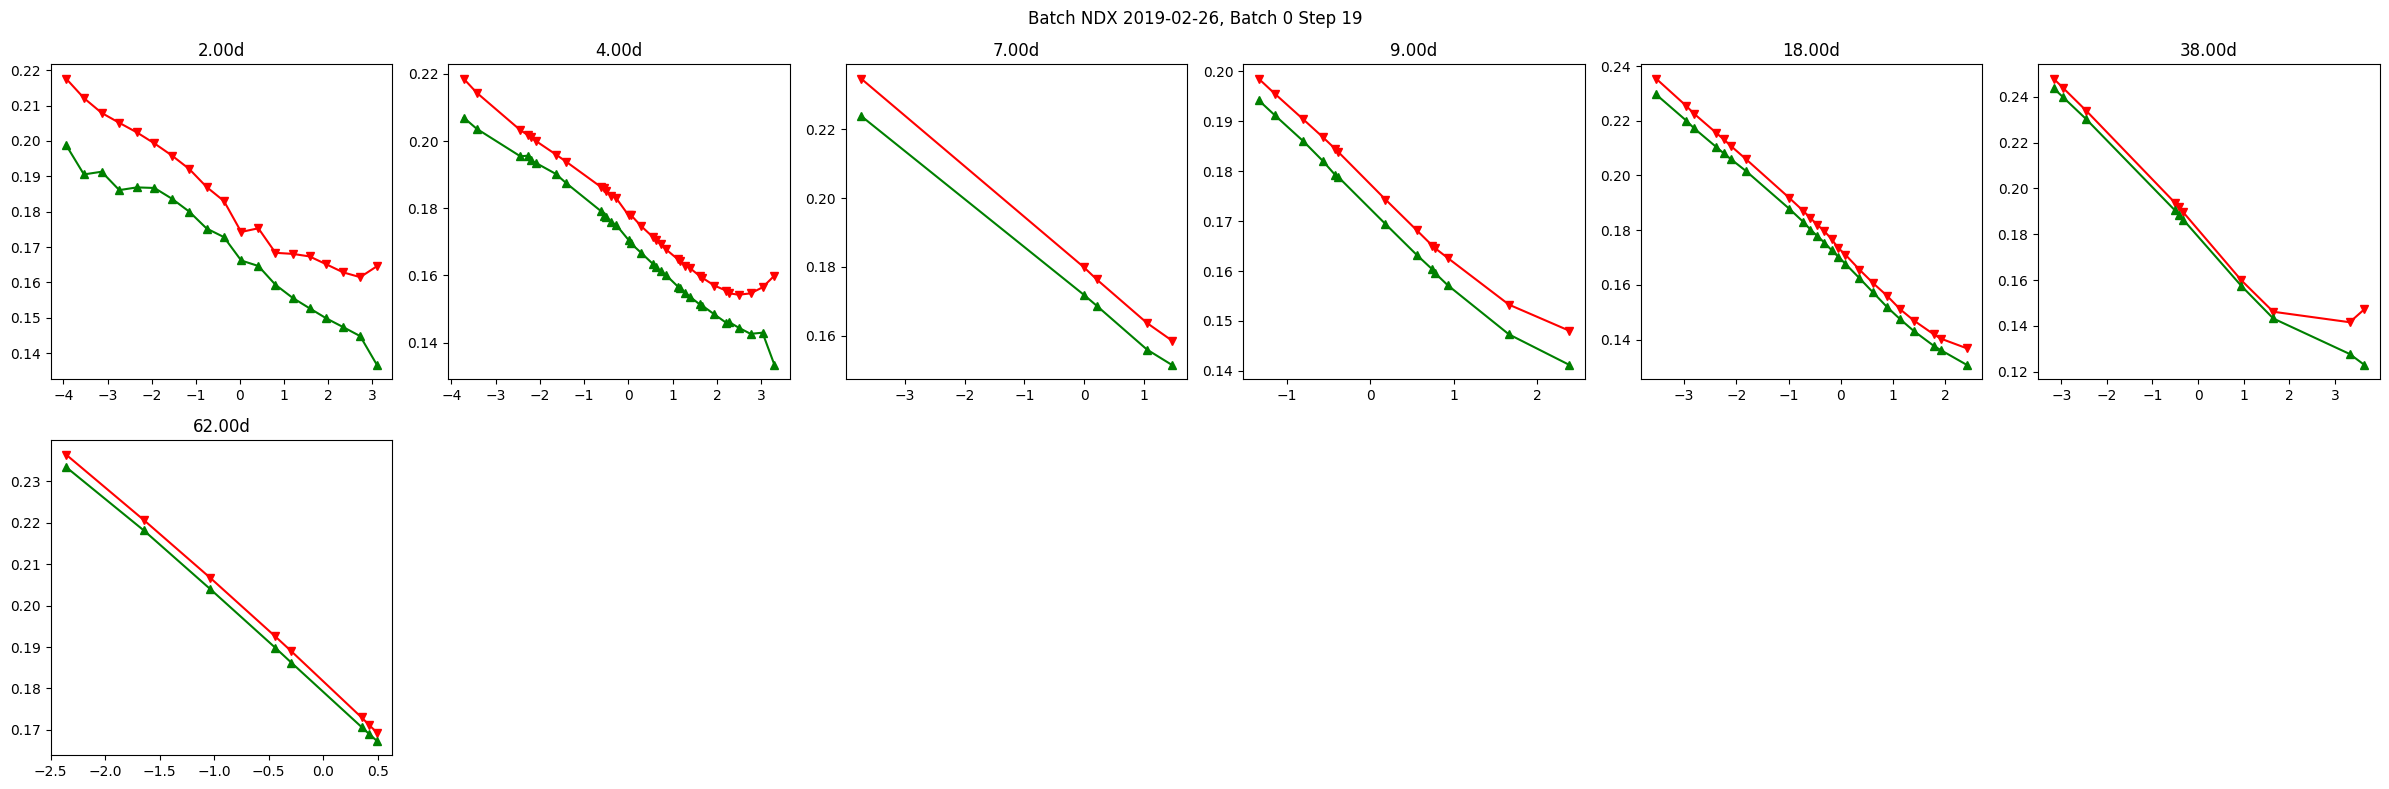

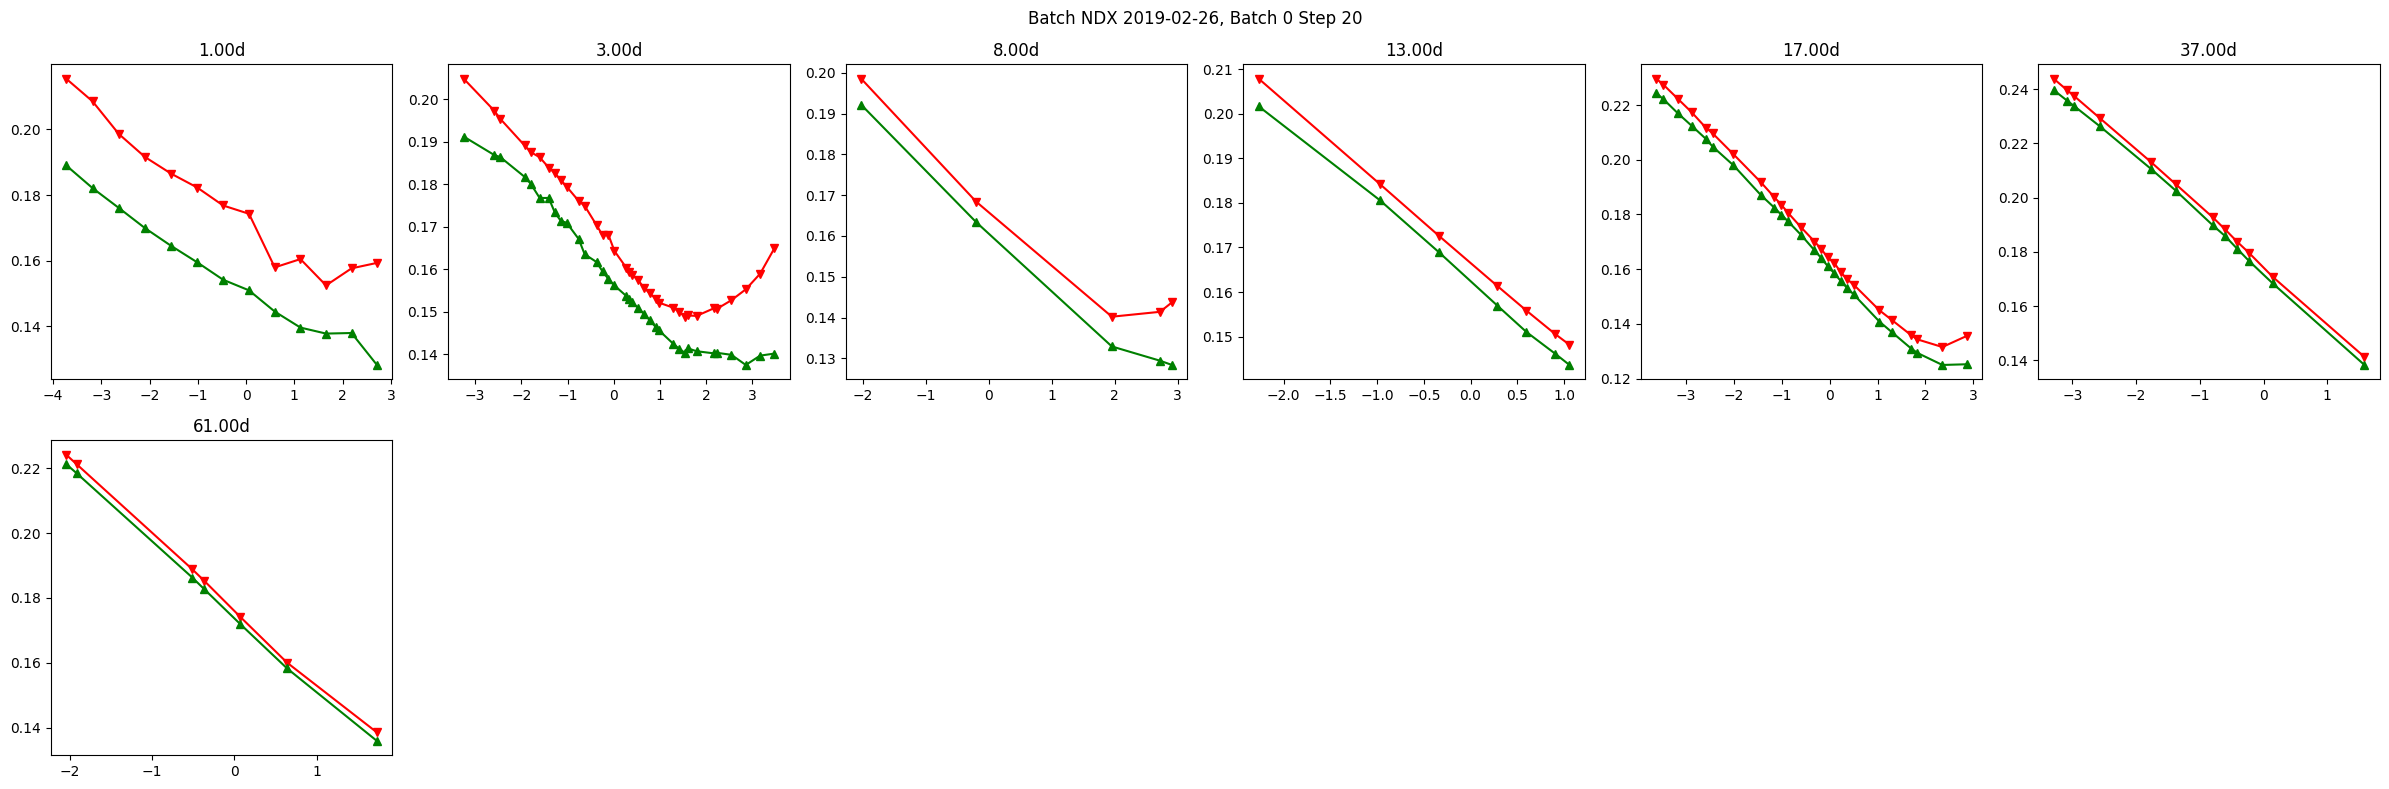

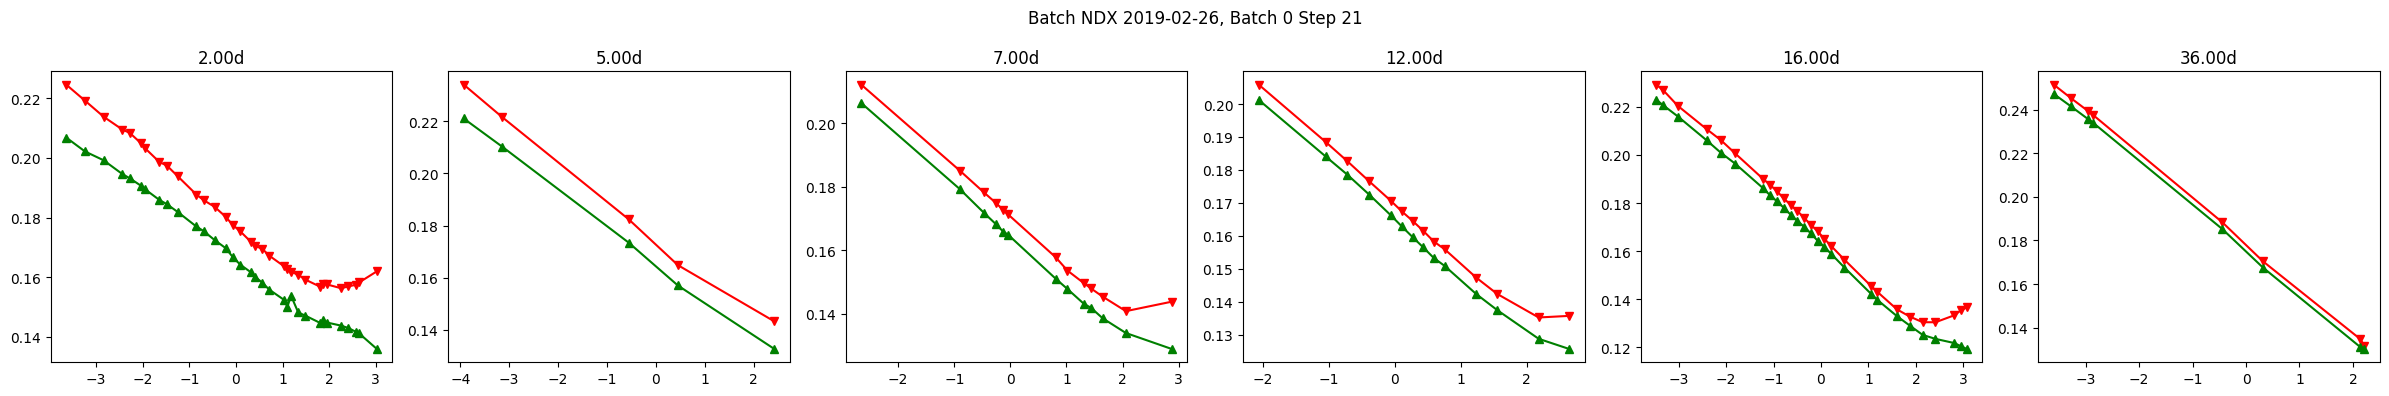

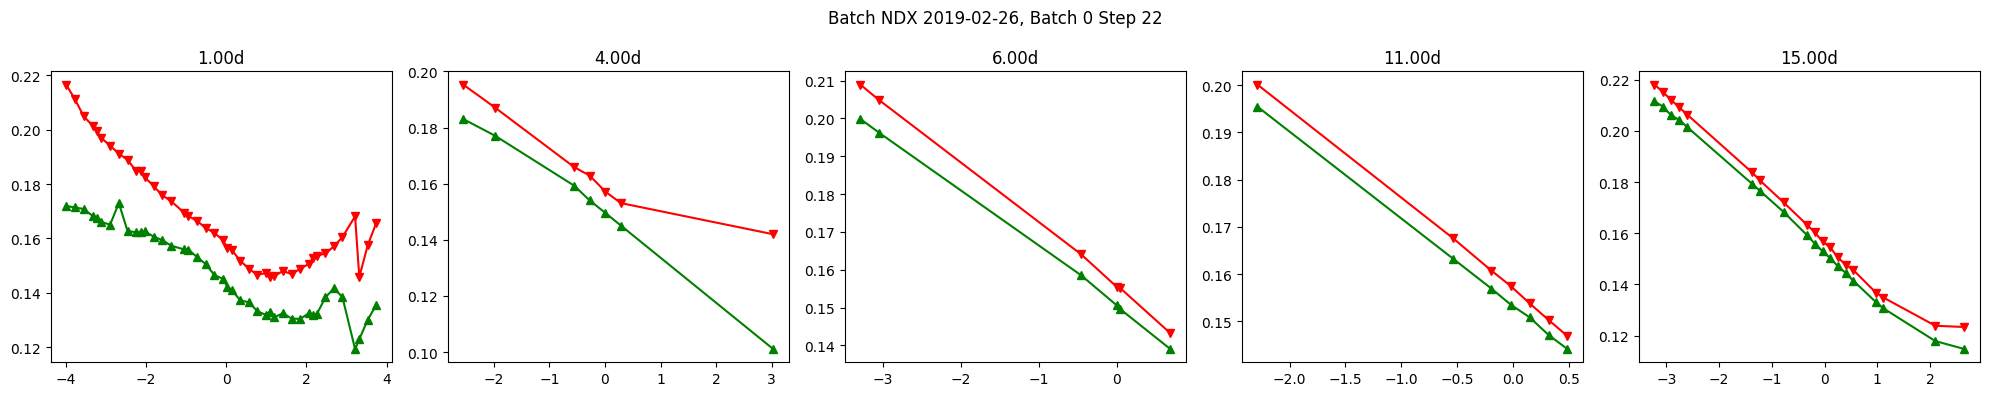

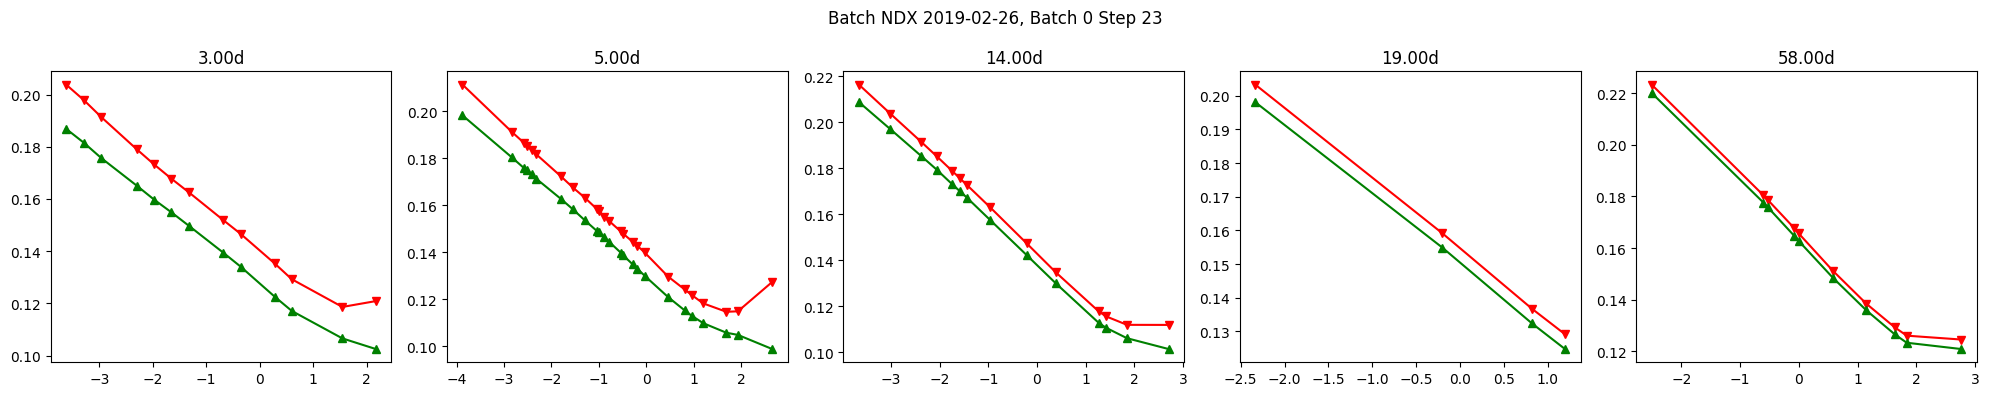

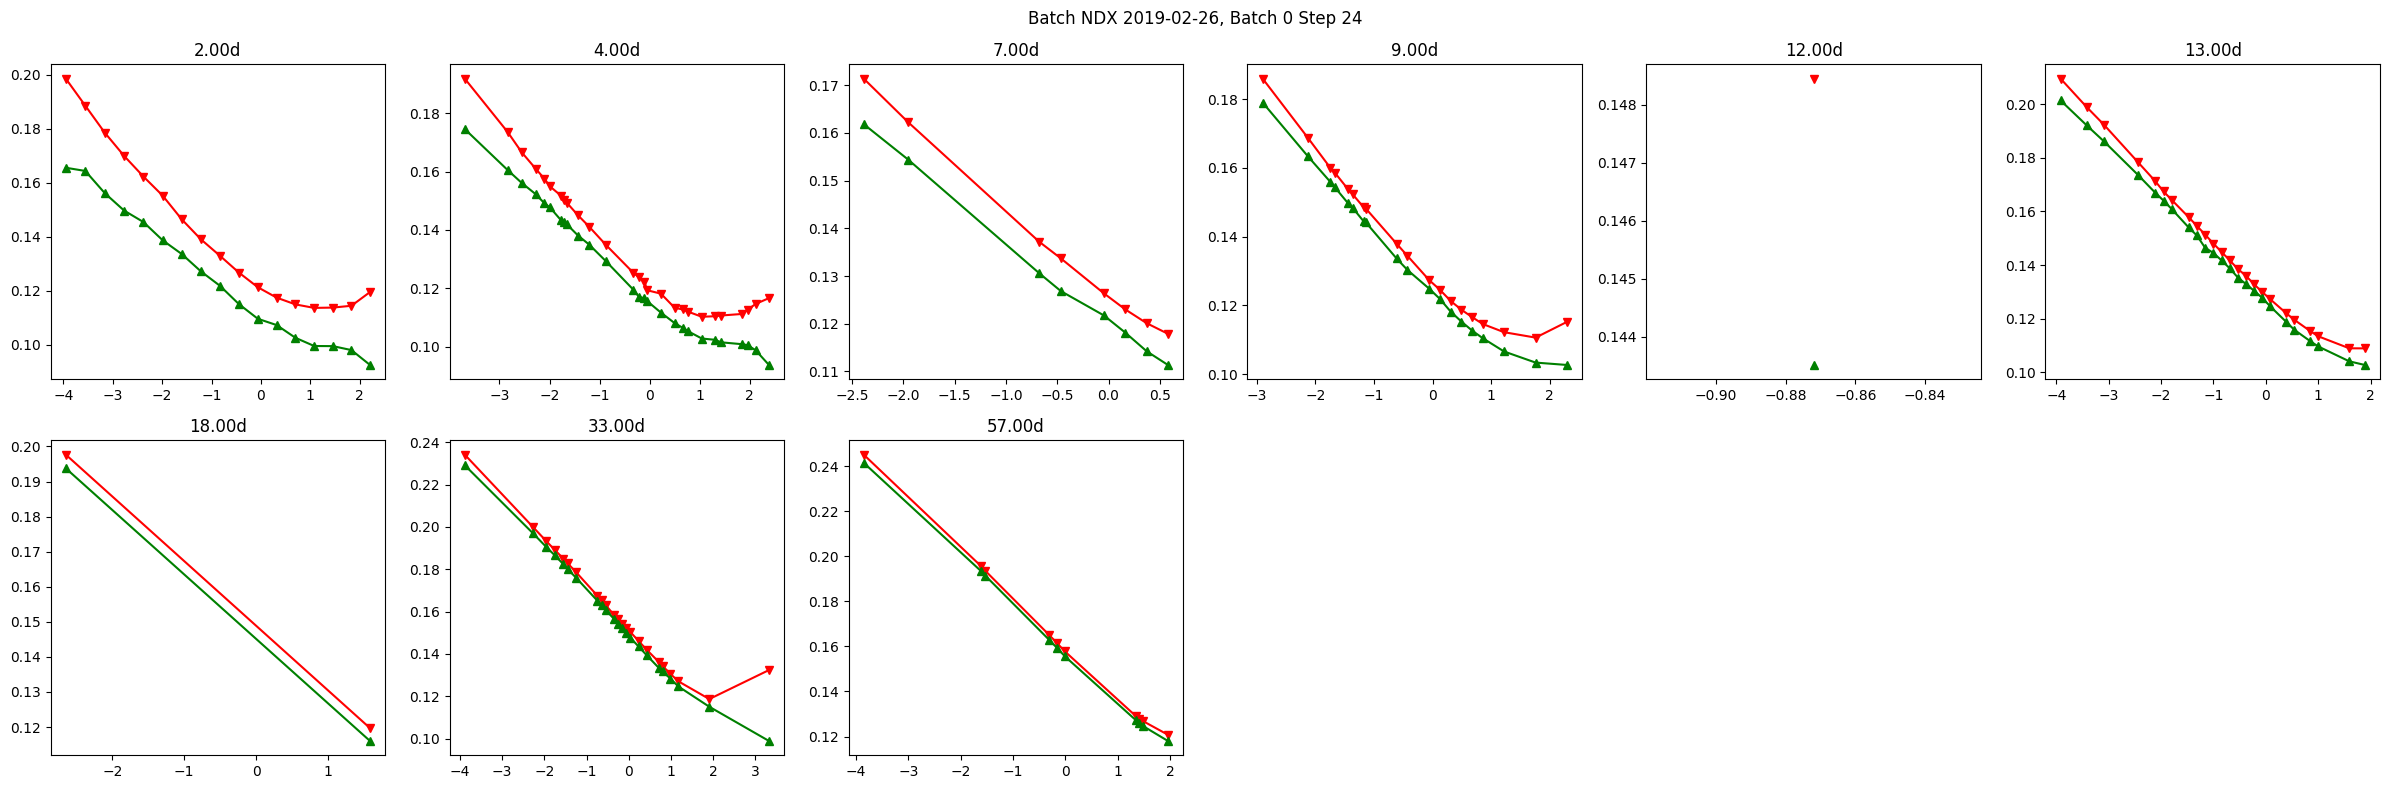

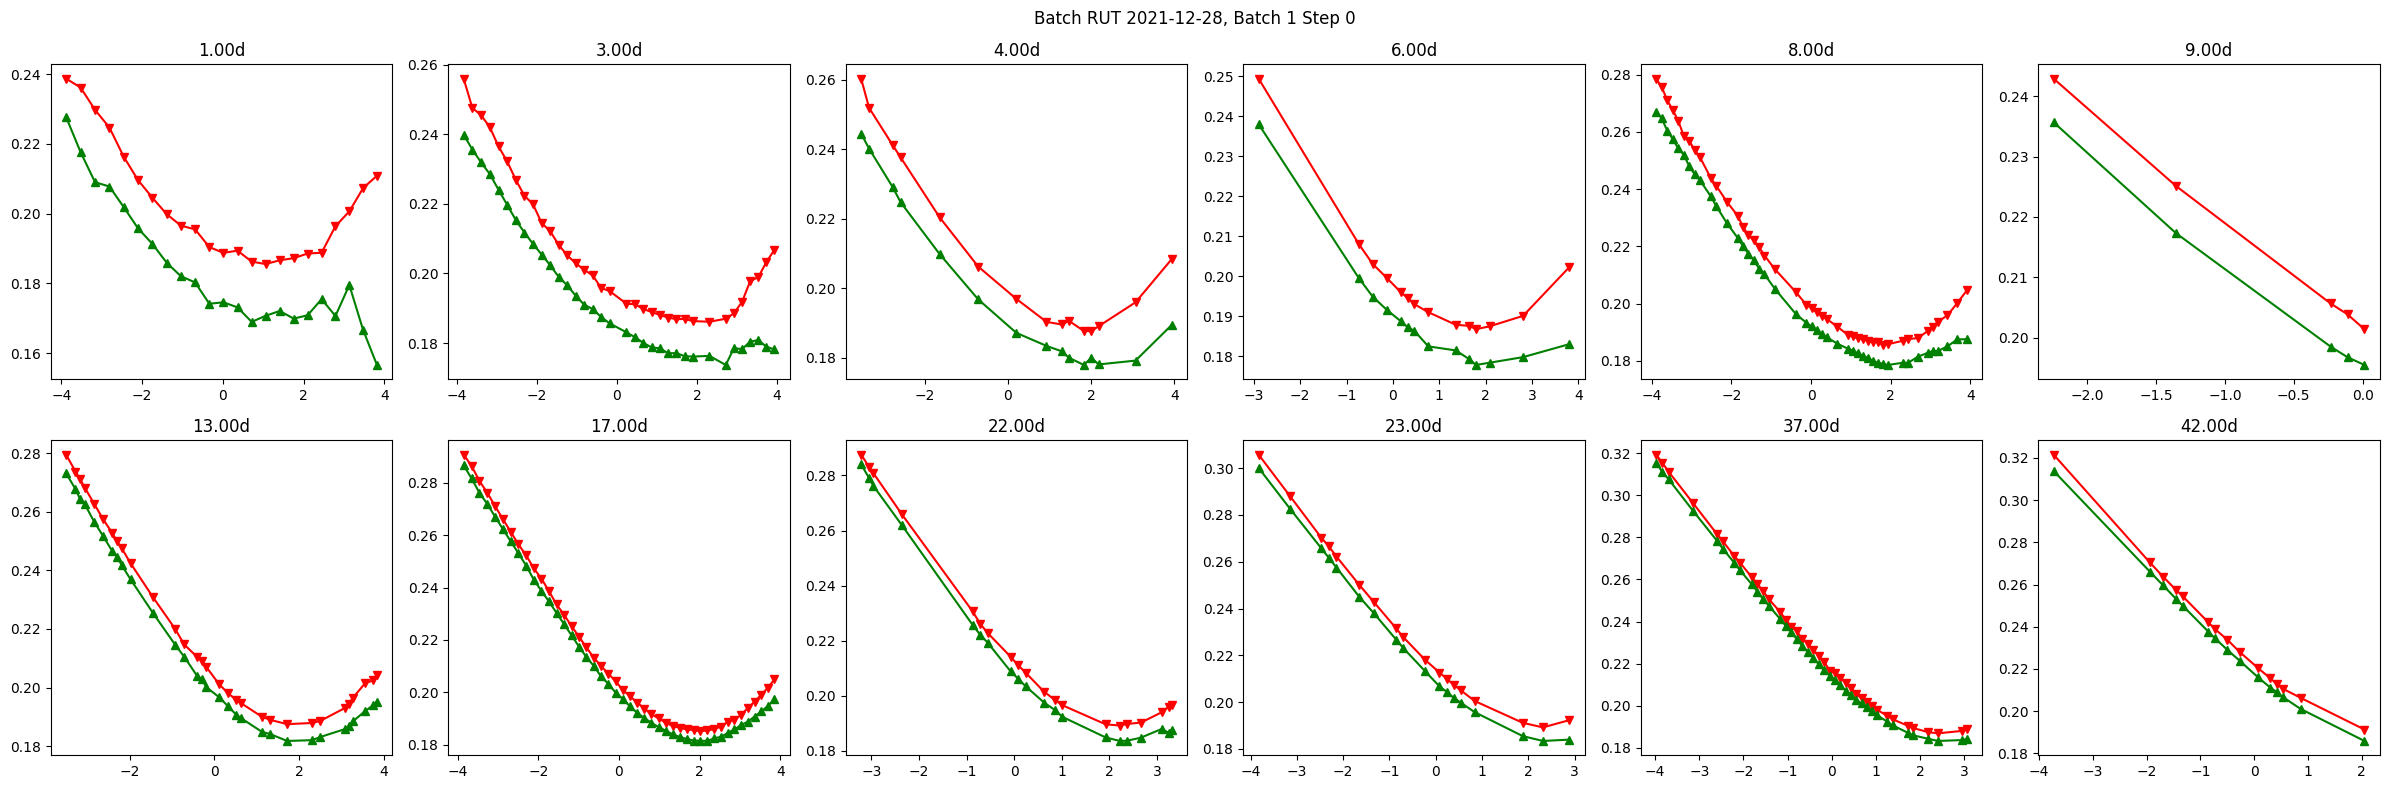

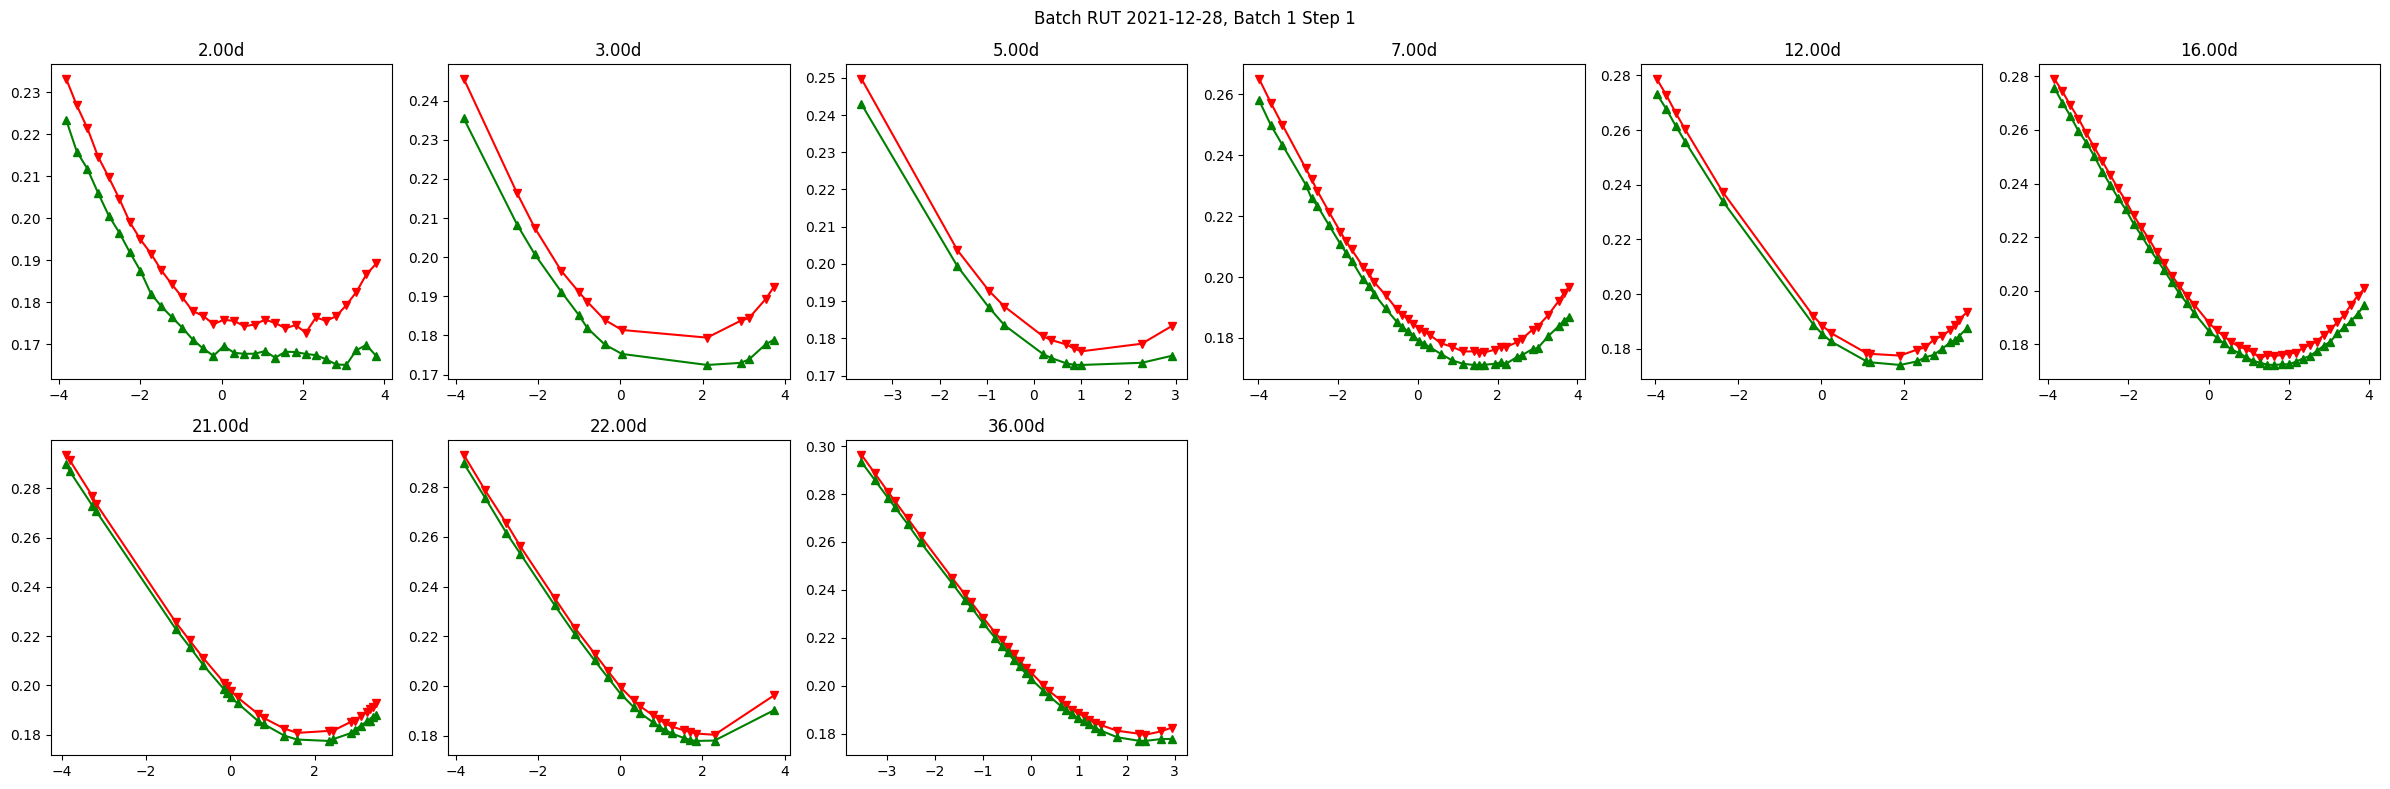

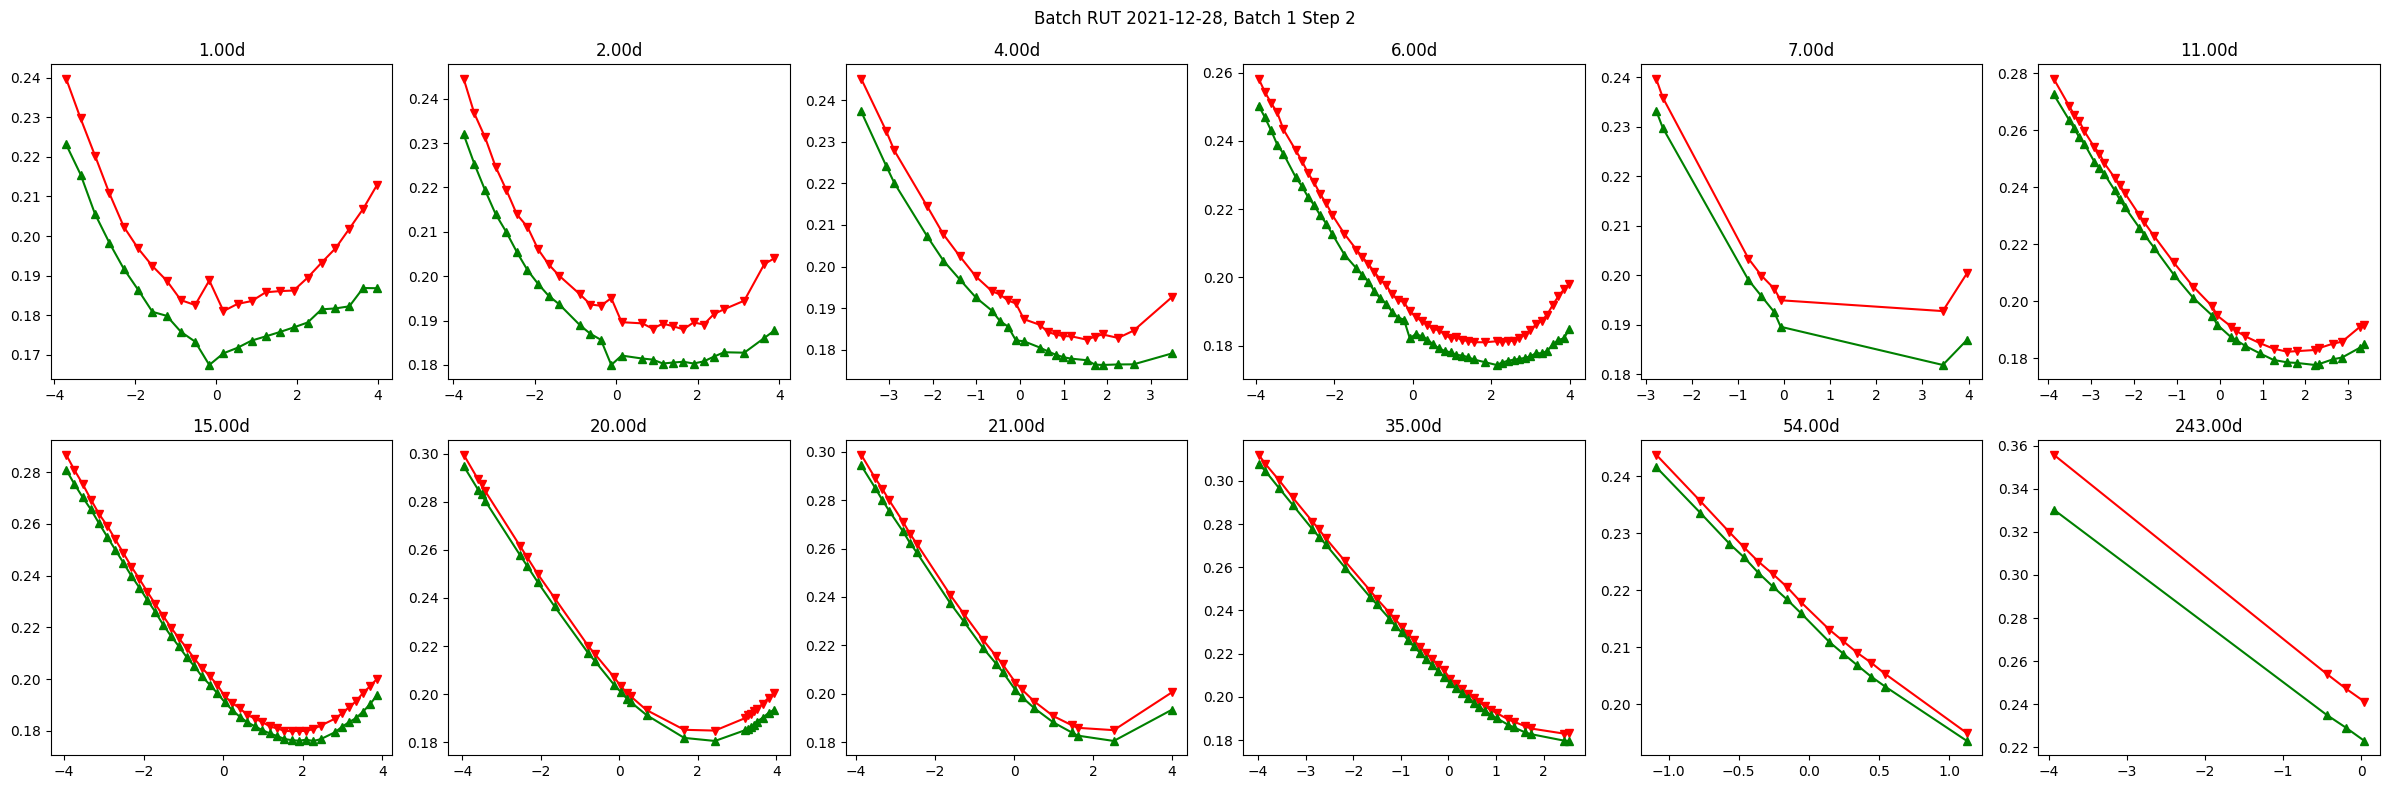

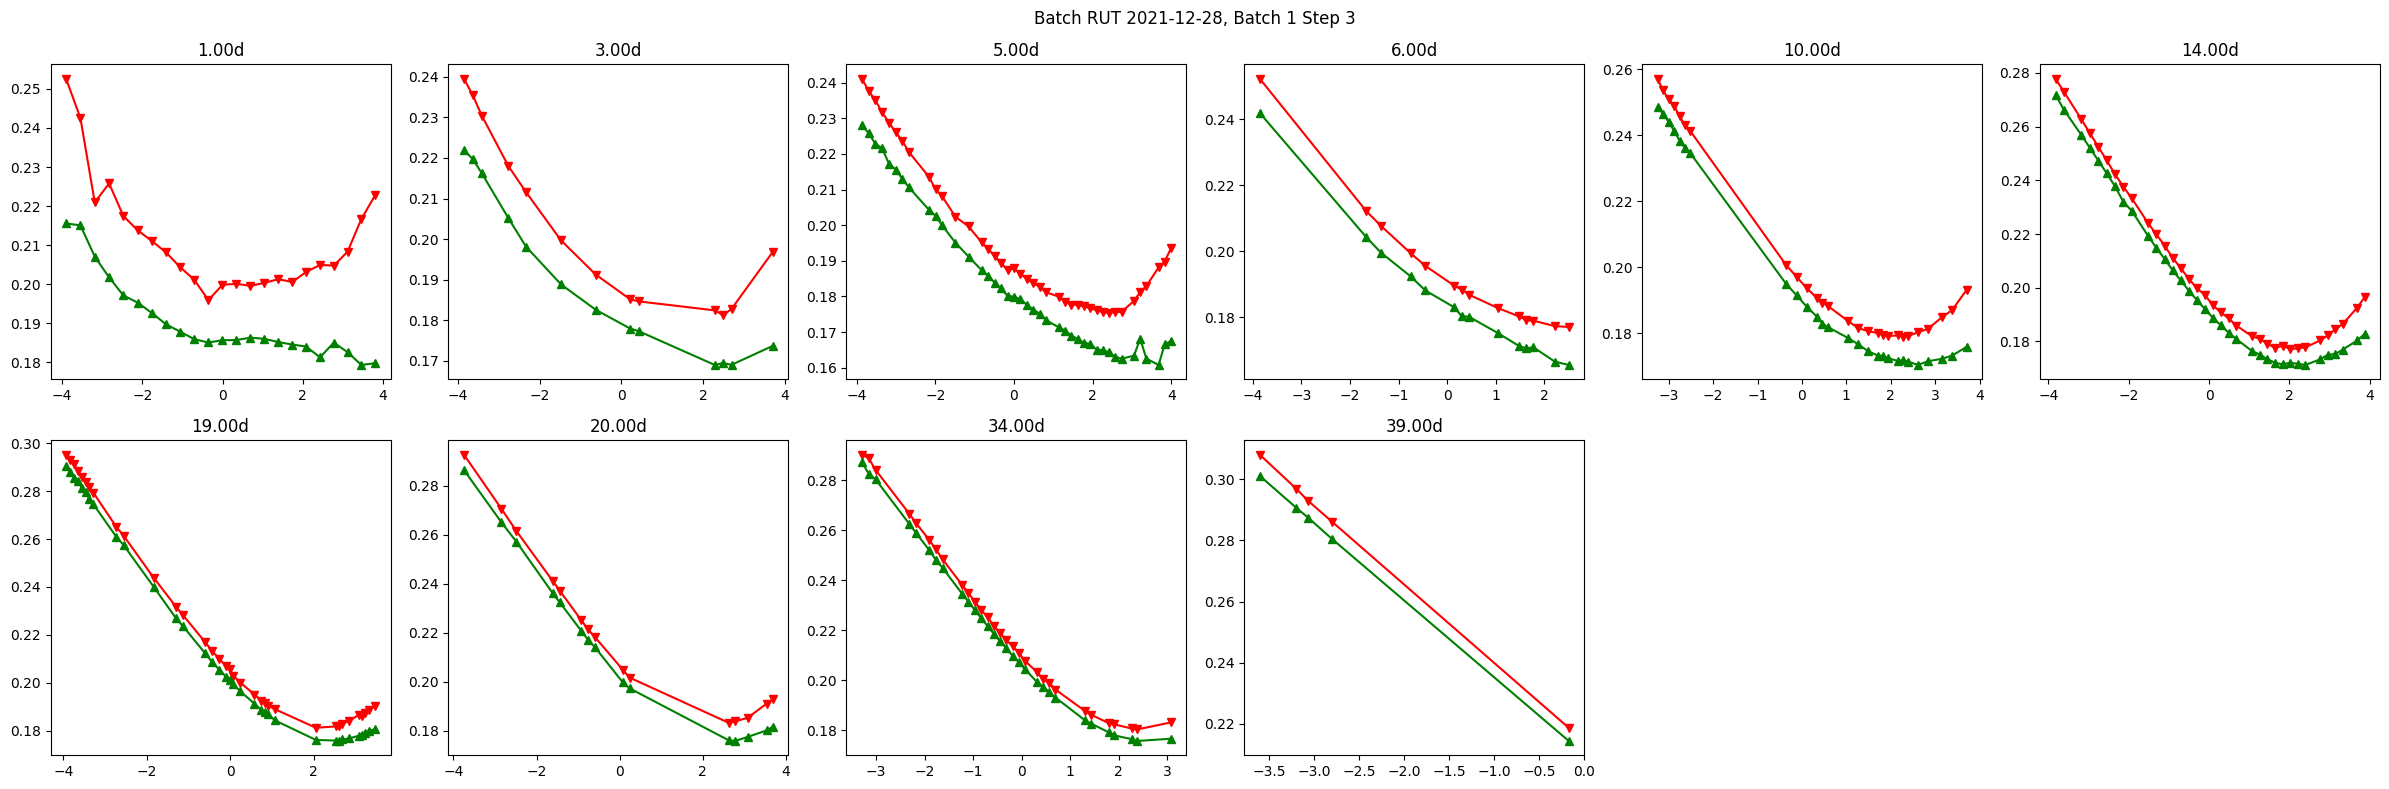

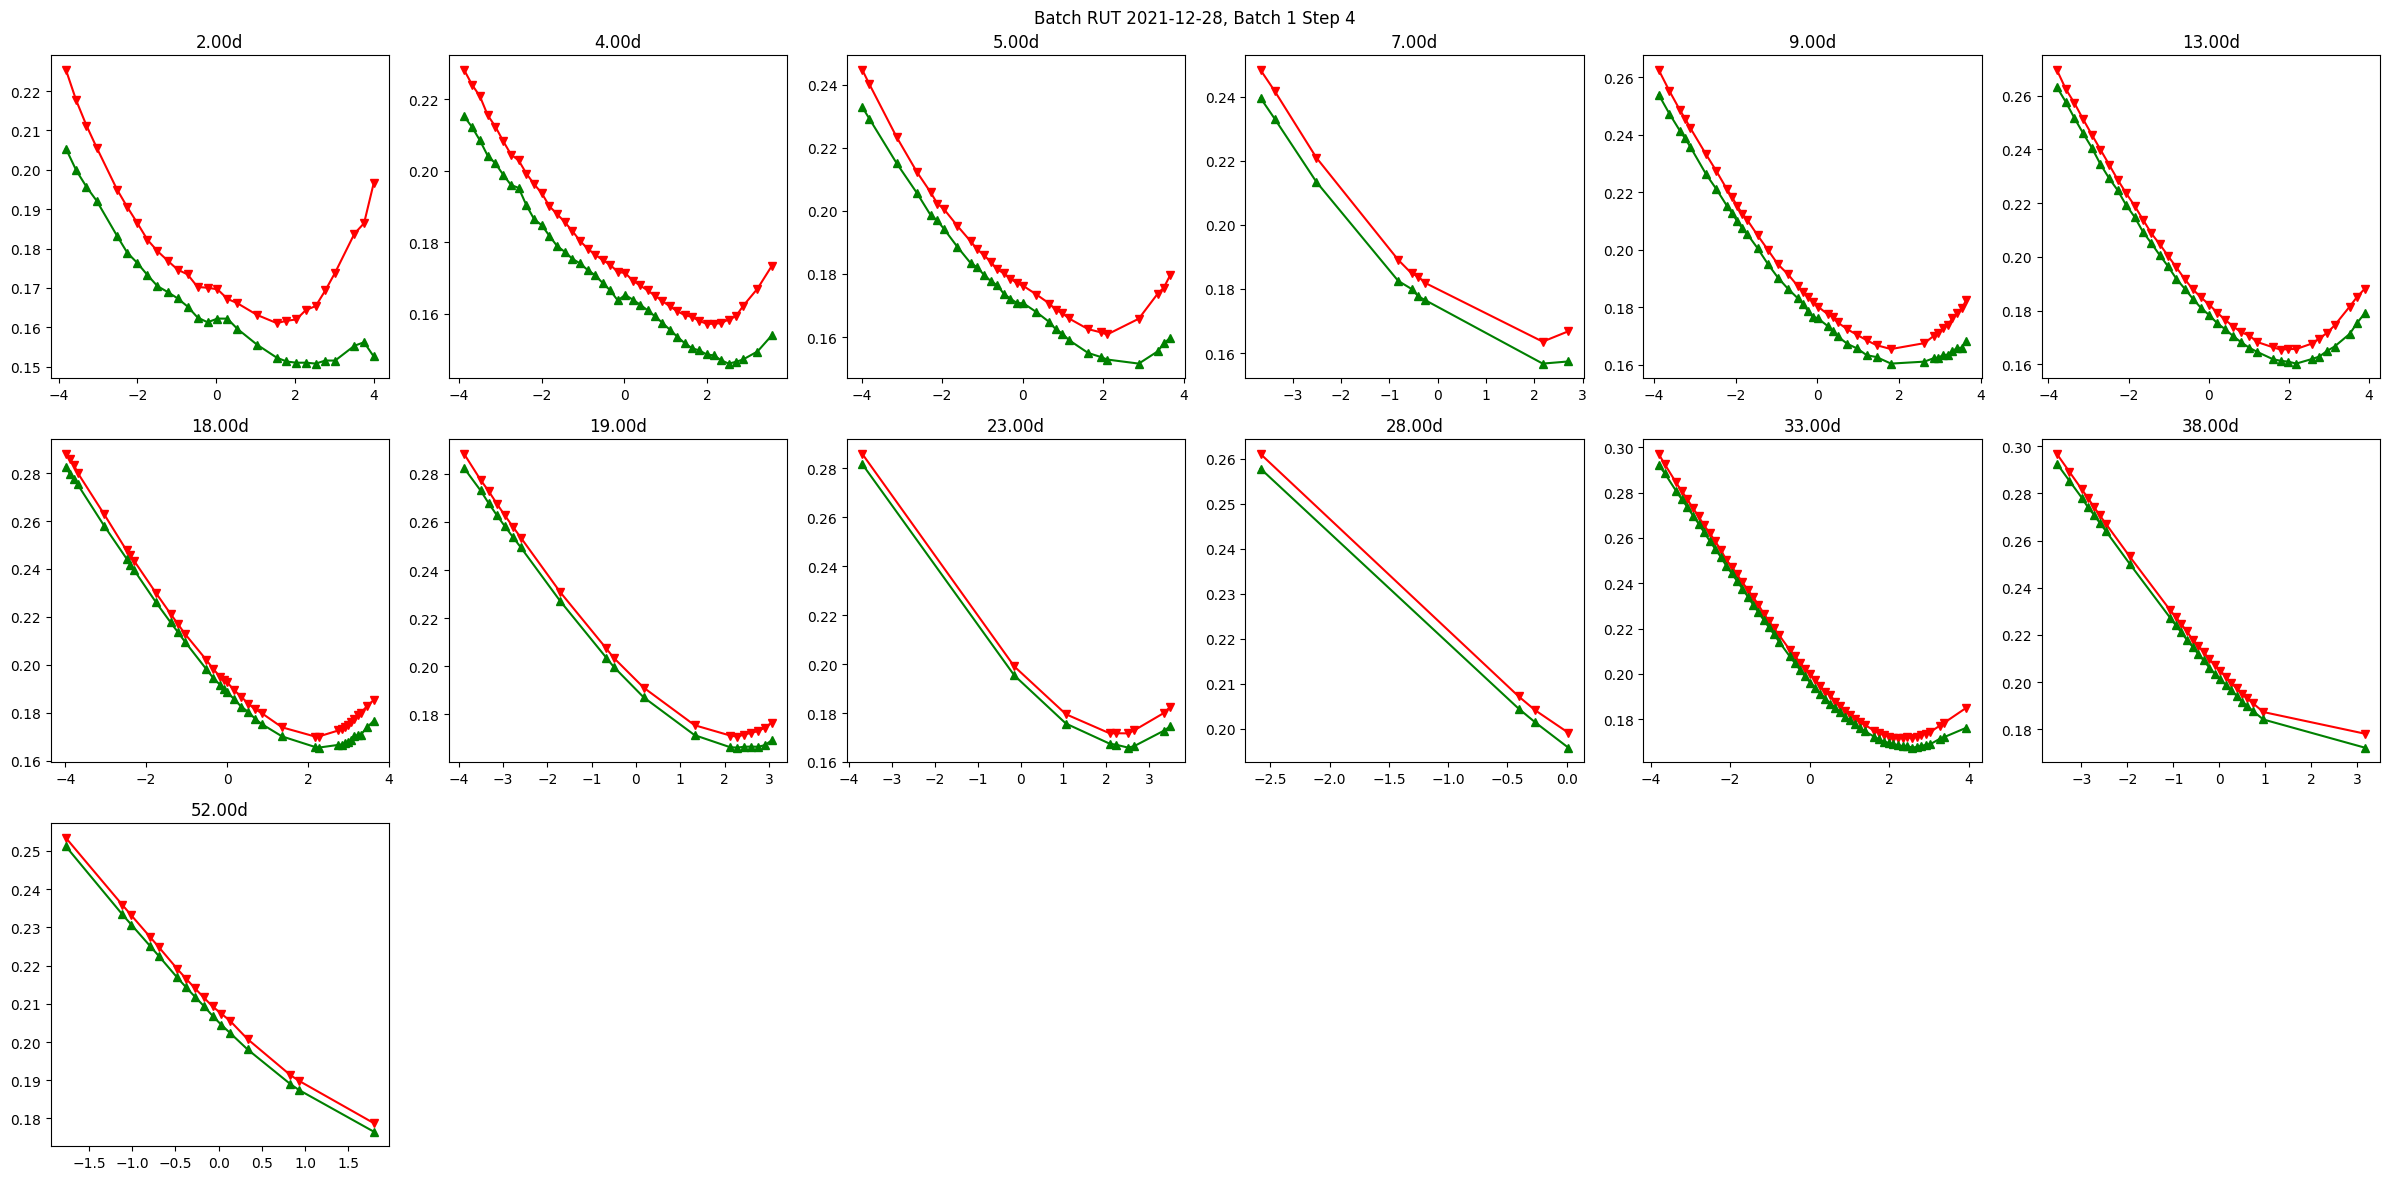

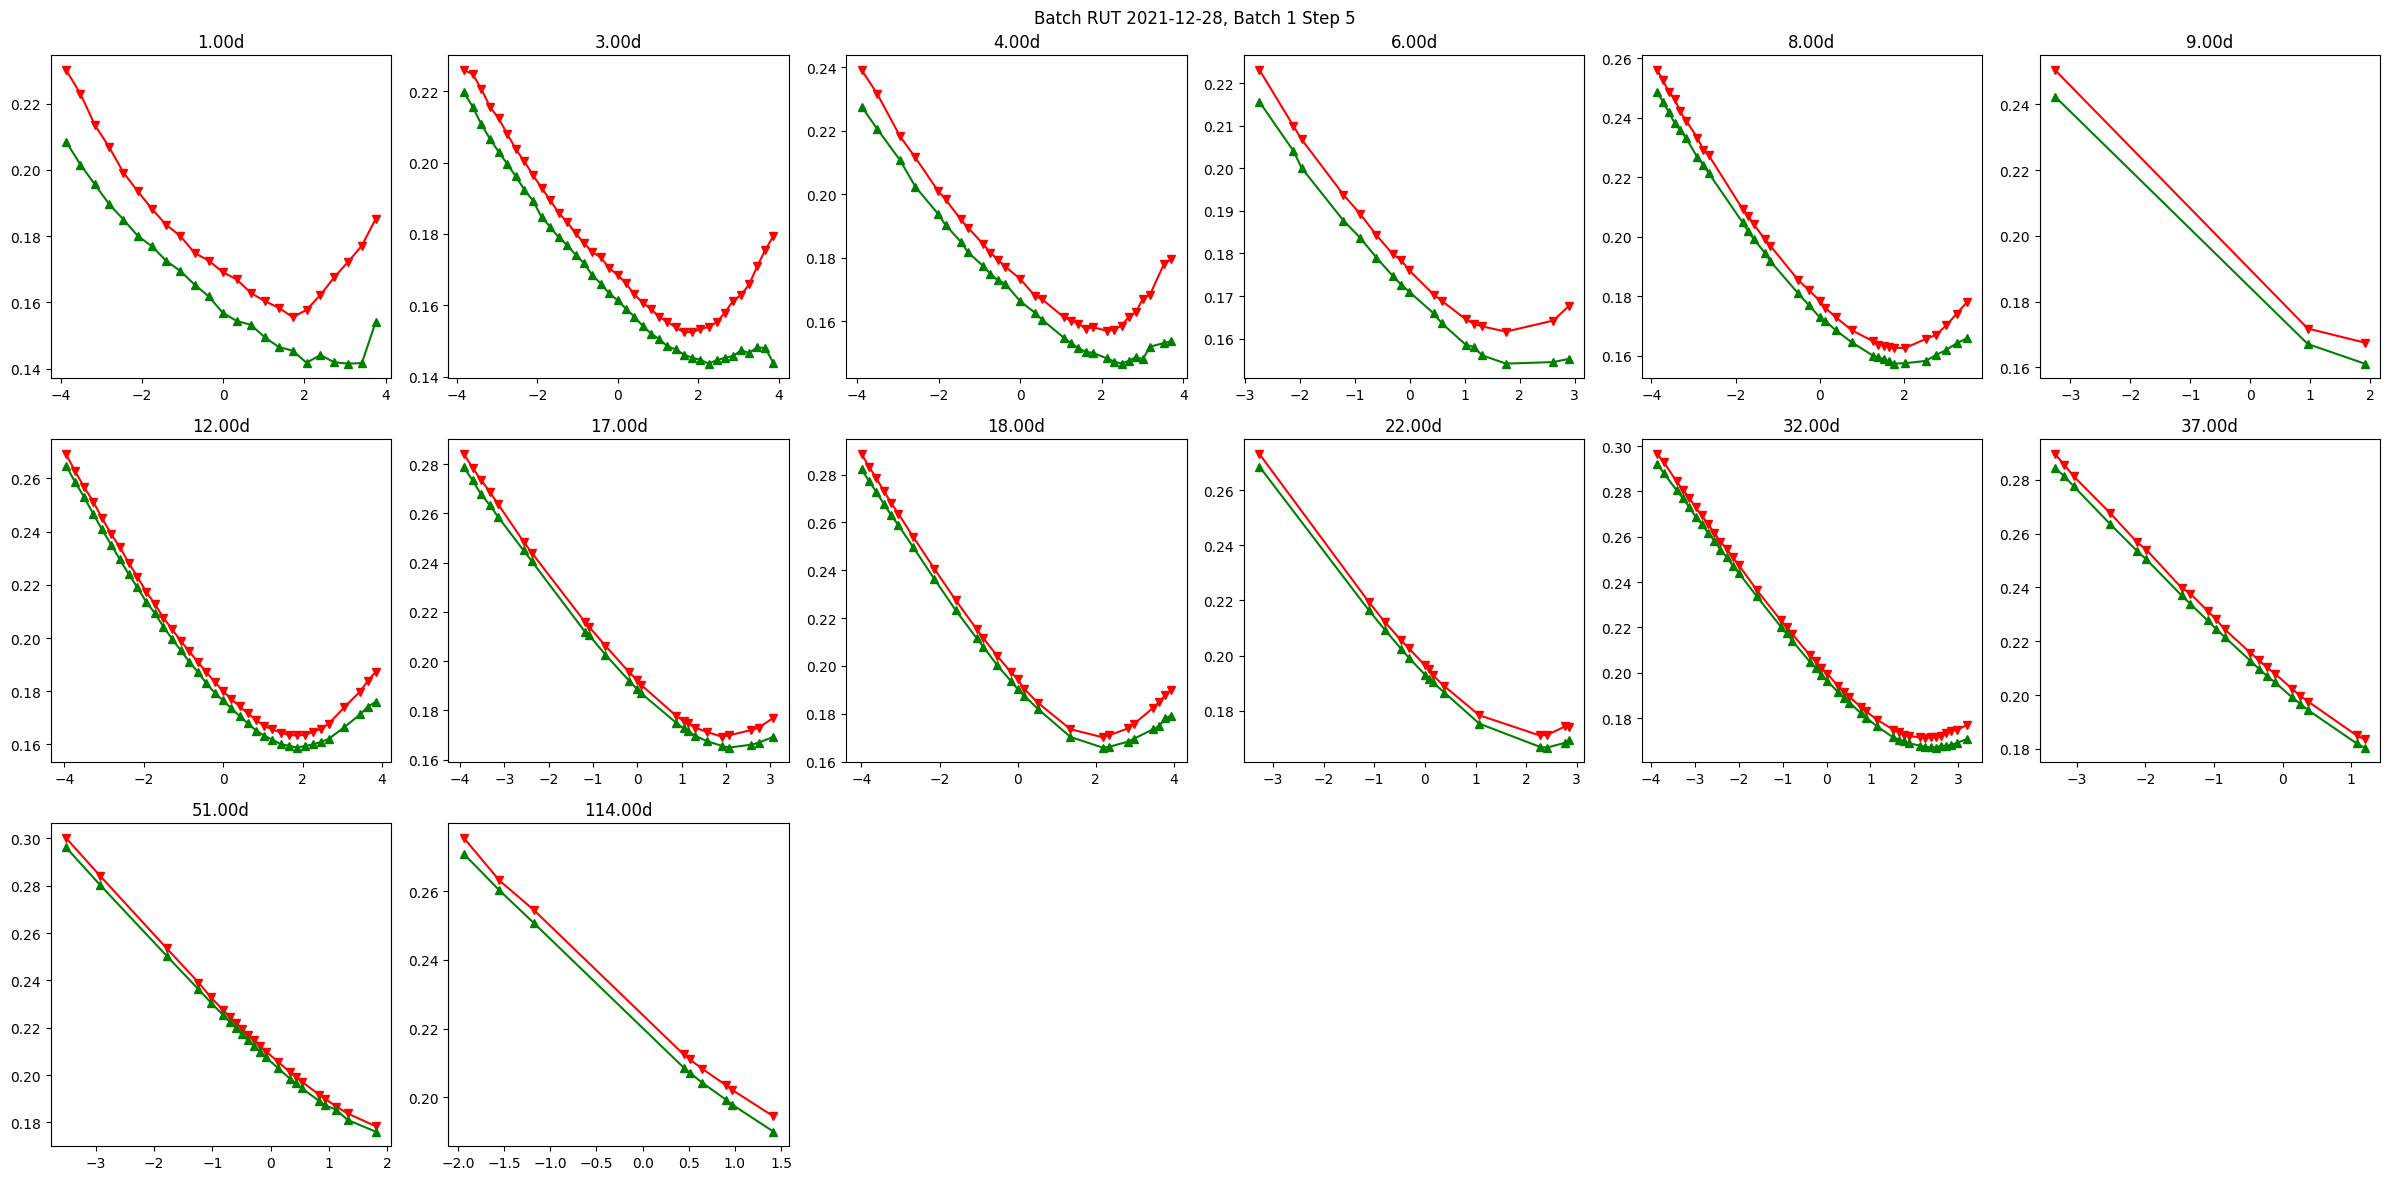

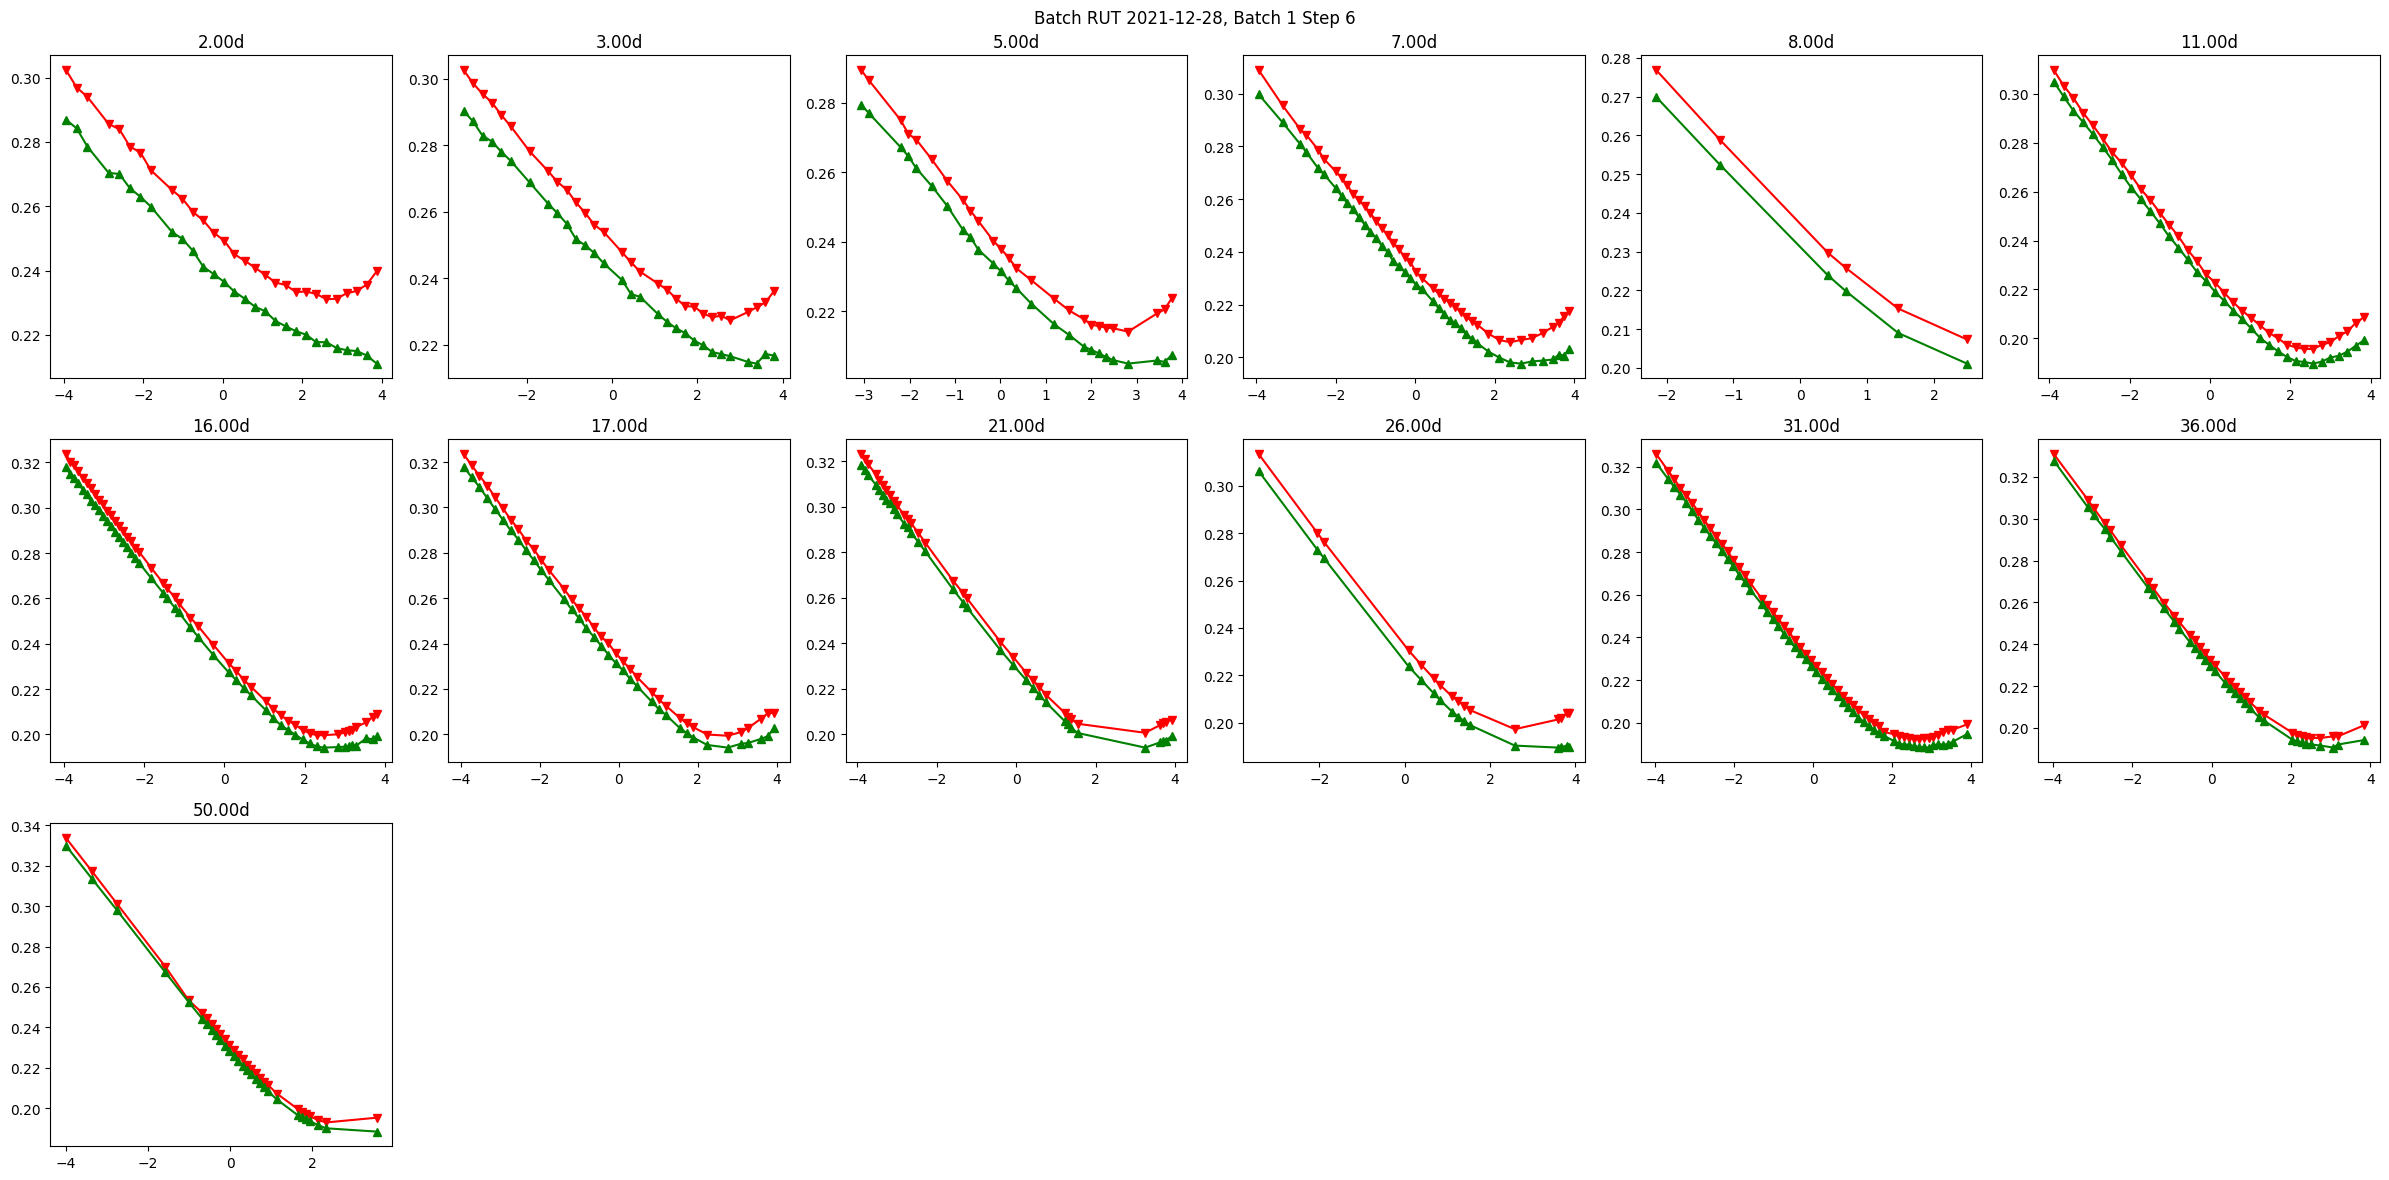

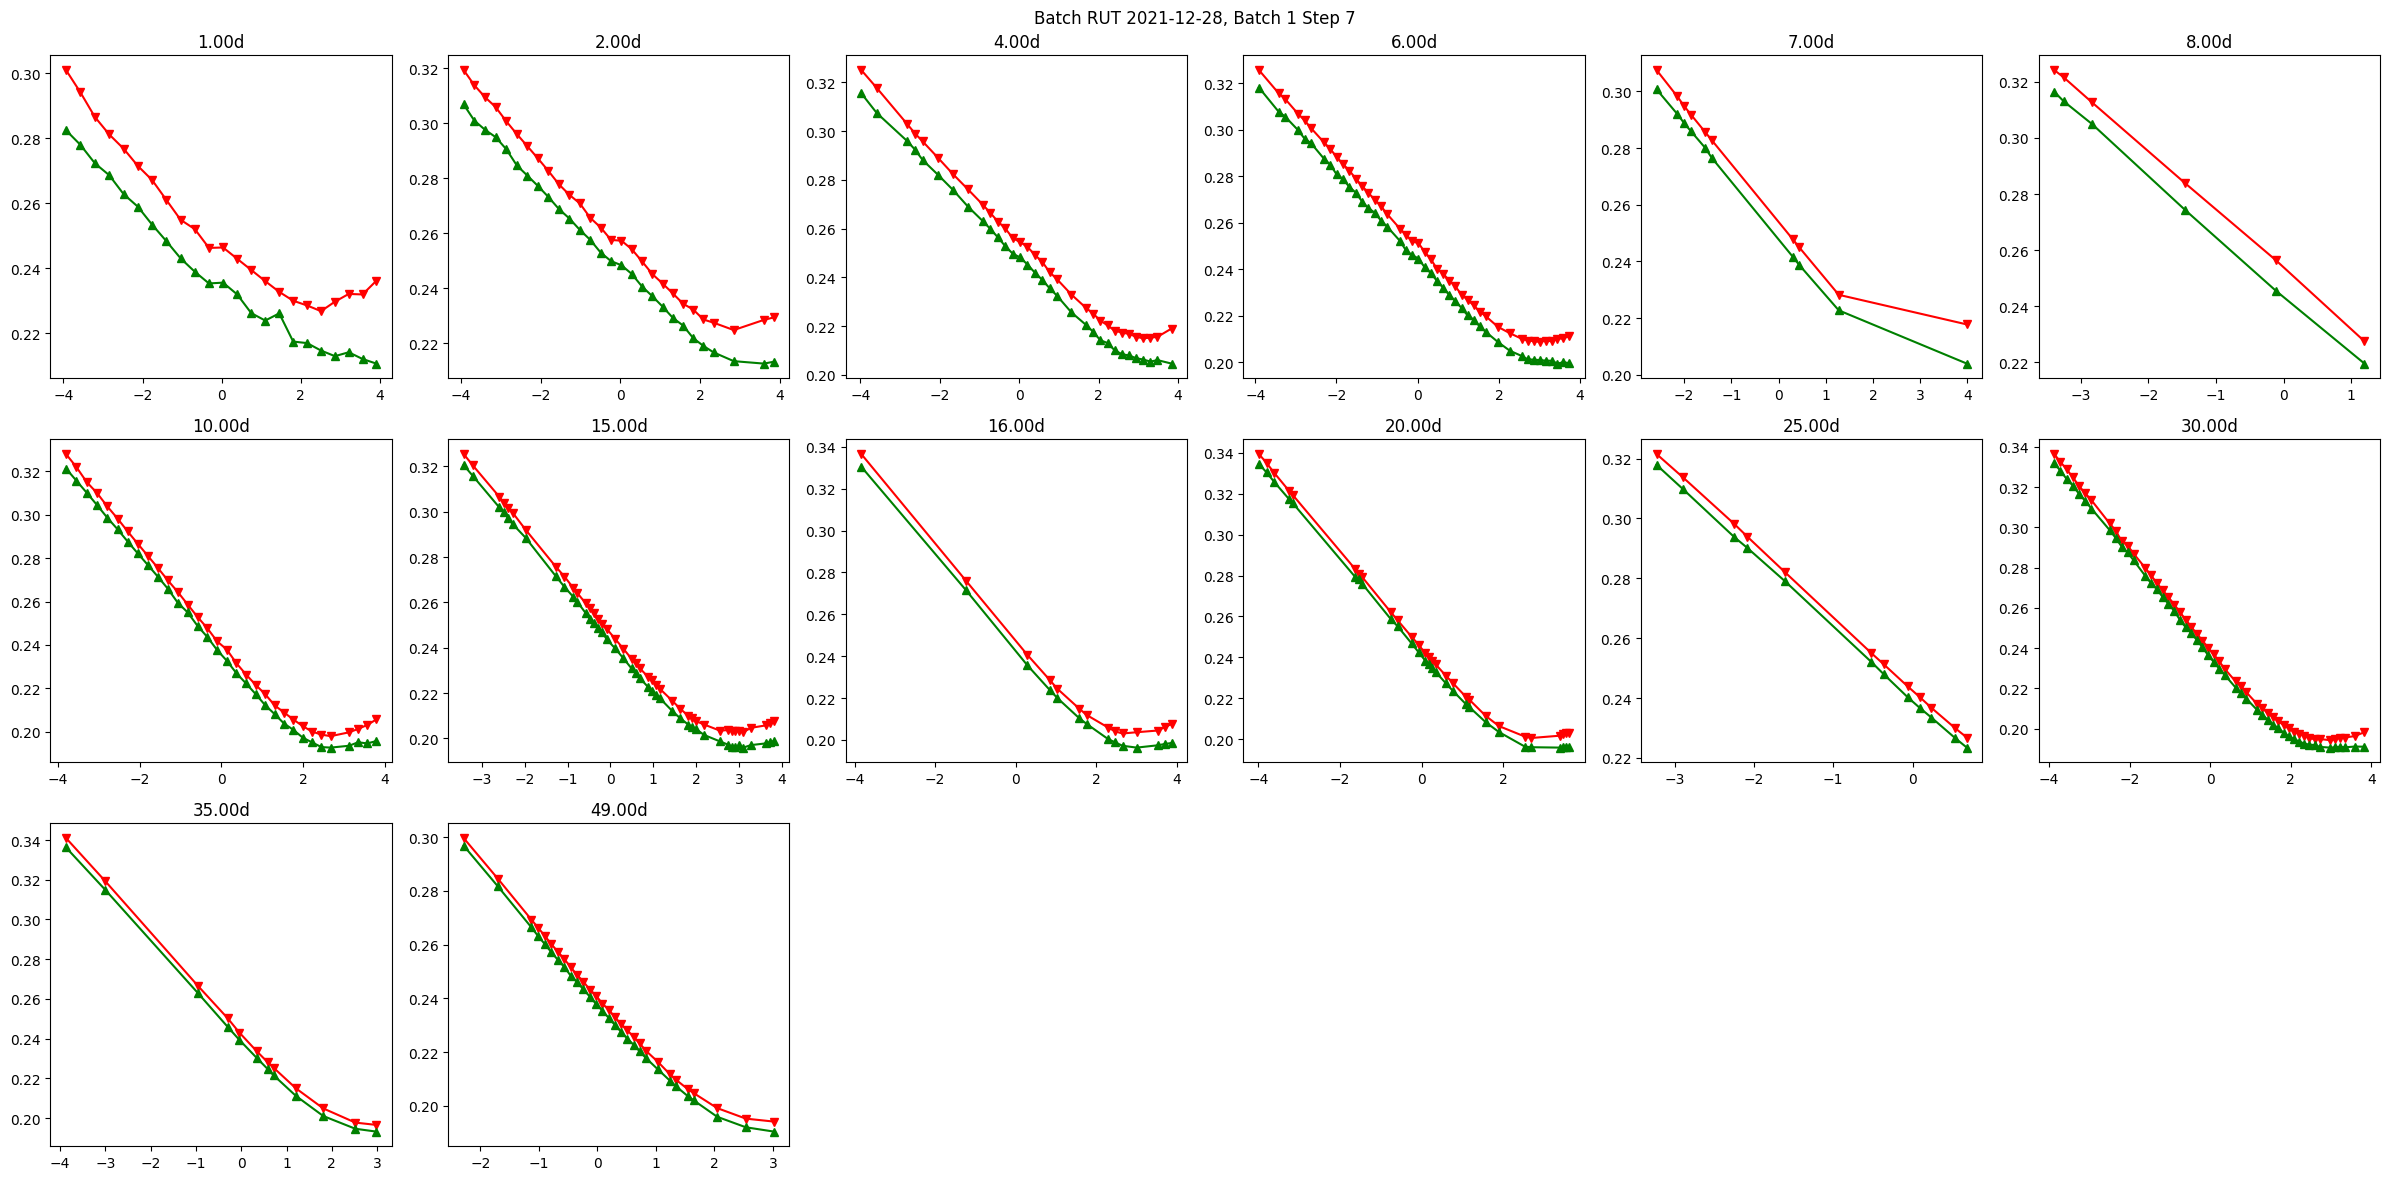

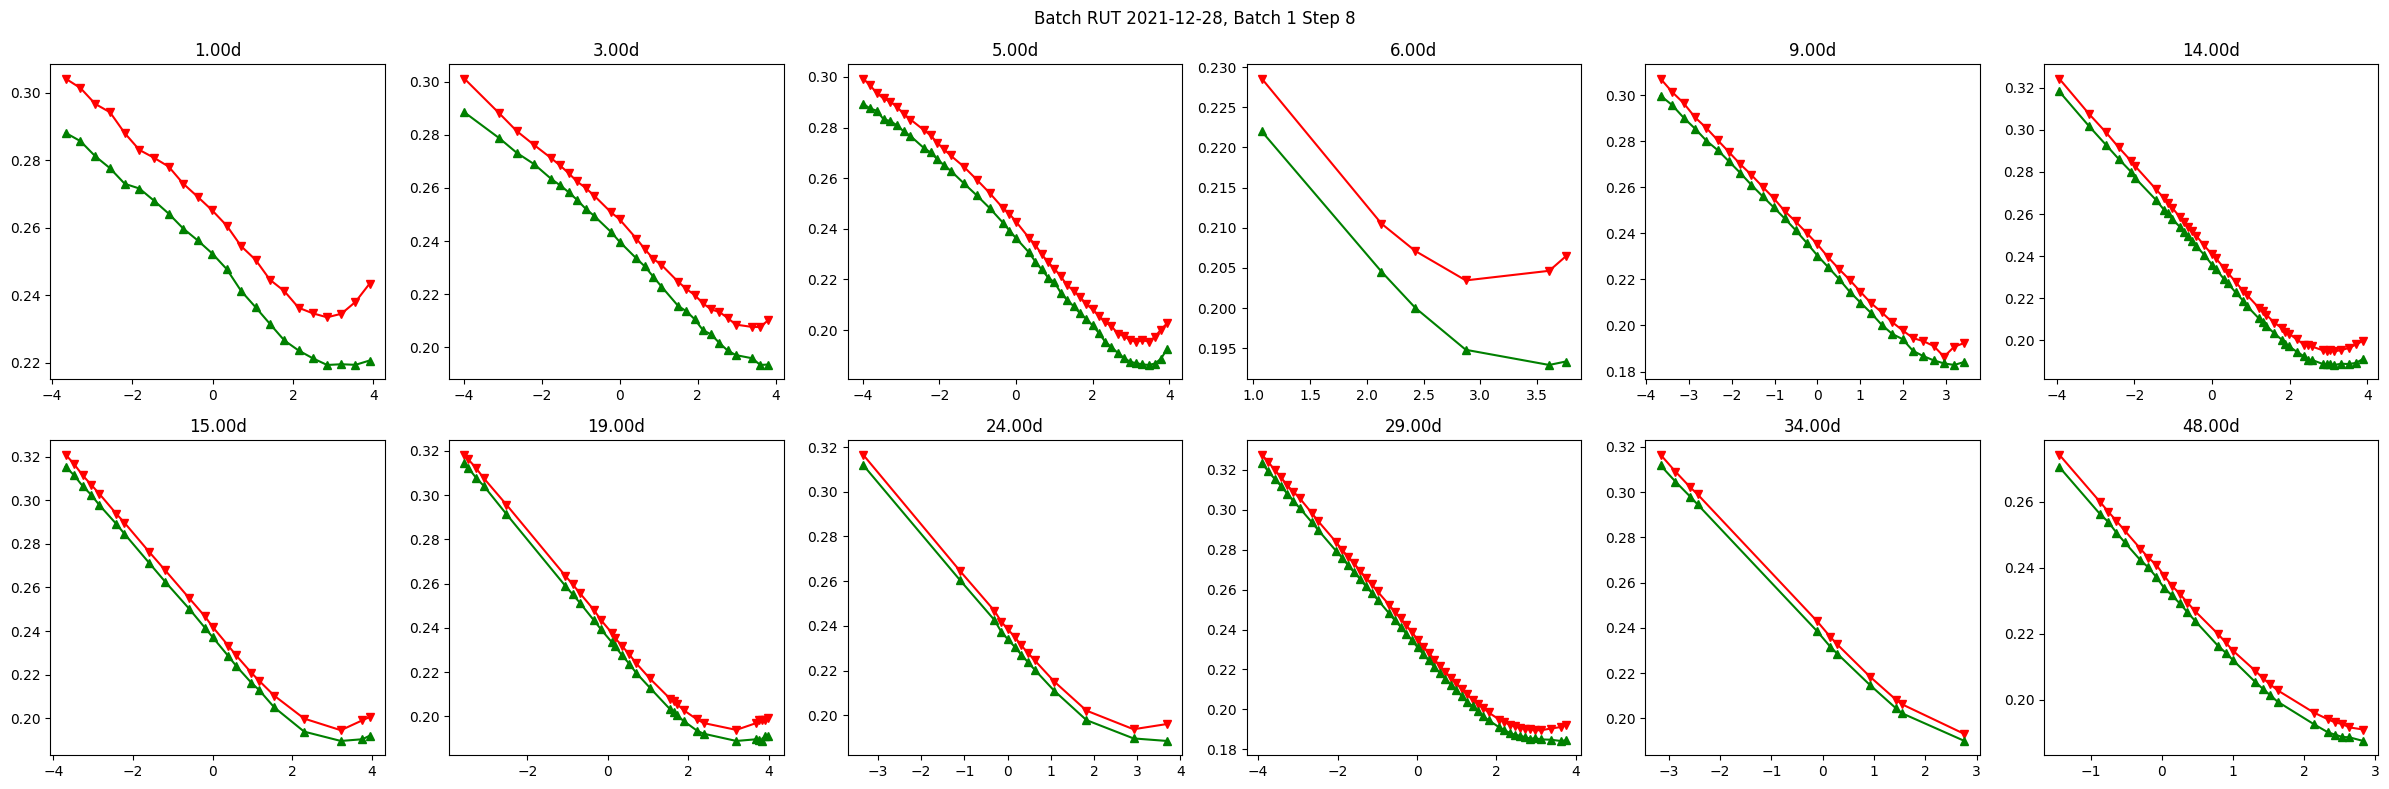

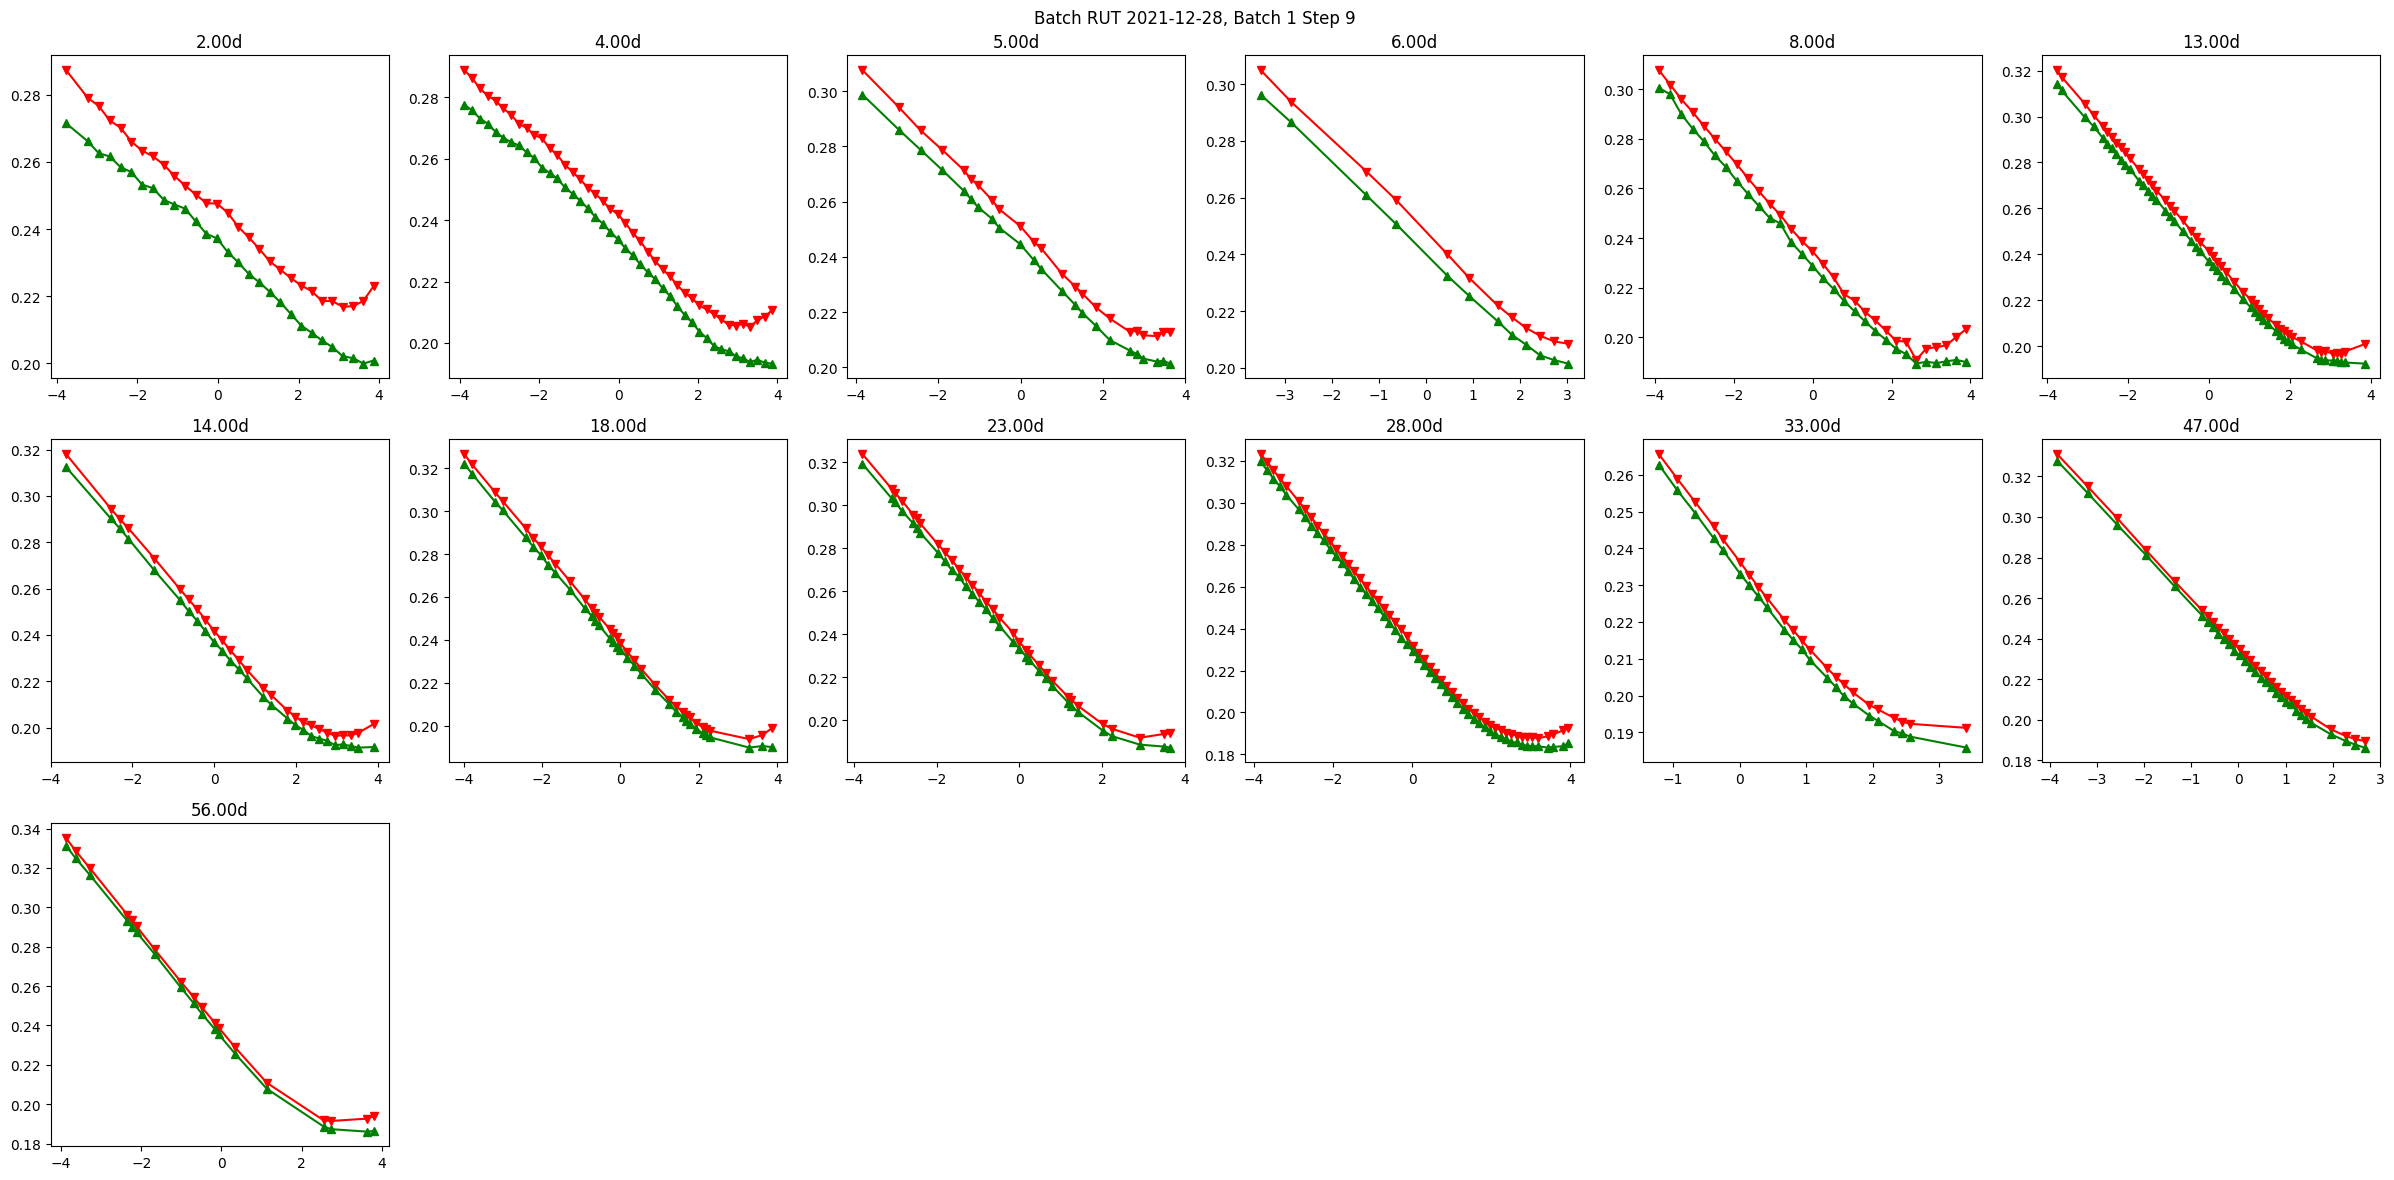

KeyboardInterrupt: 

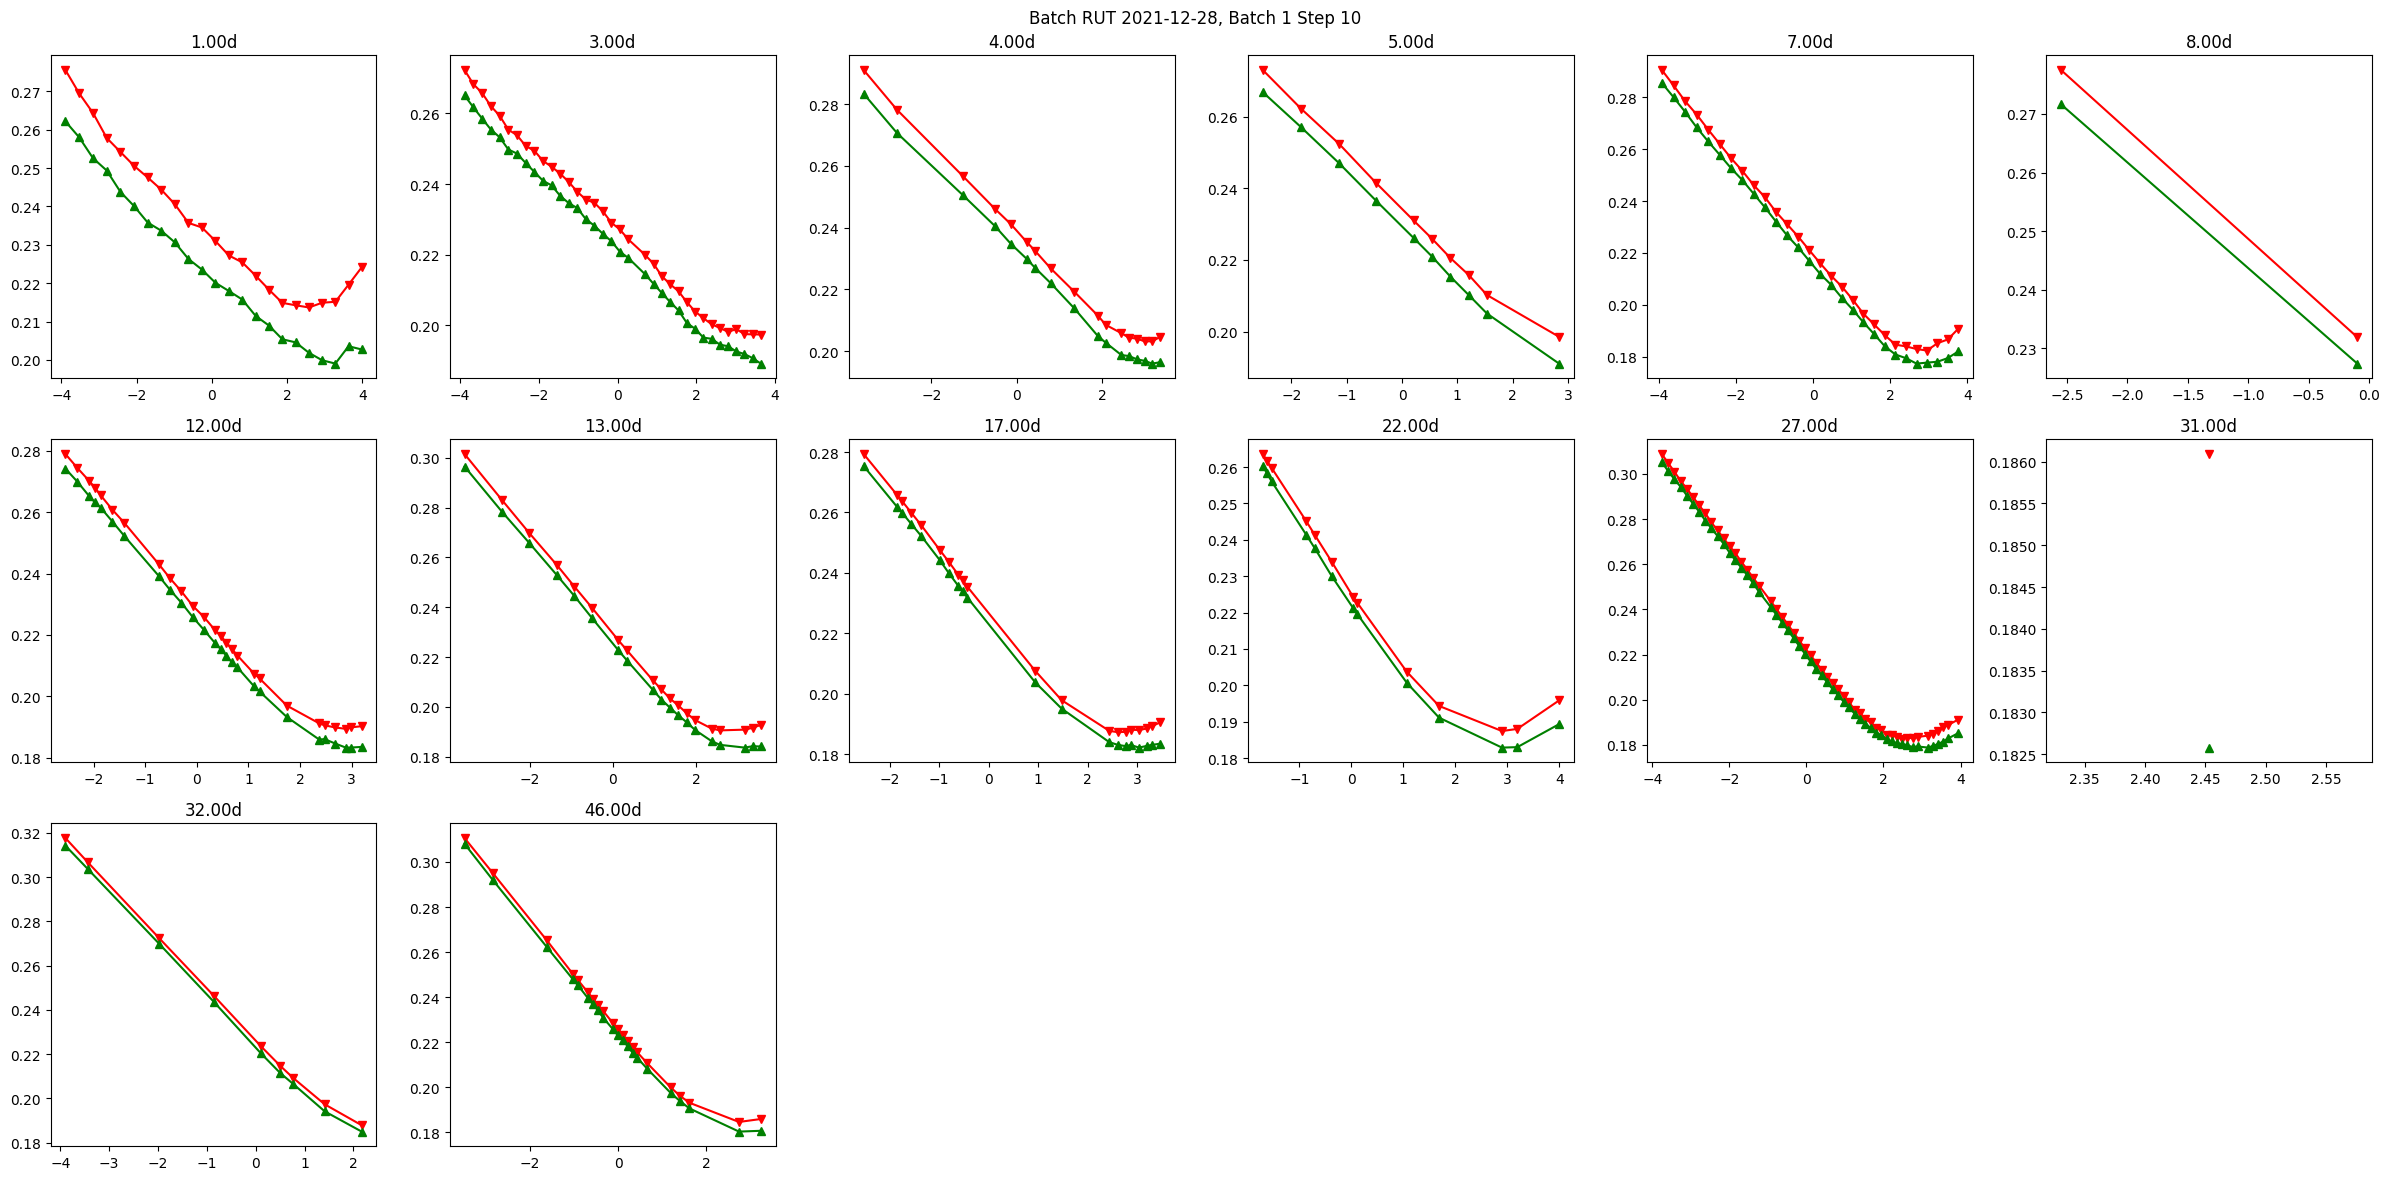

In [12]:
from prettytable import PrettyTable
from cdxcore.util import fmt_list, fmt_big_byte_number
from cdxcore.dynaplot import figure

def viz_batch():
    print("Loading torch...", end='', flush=True)
    import torch as torch
    import numpy as nnp
    print("done.")
    g = torch.Generator(device="cpu")
    g.manual_seed(1234)
    batch_size = 10
    batch_ids, batch = sampler(g, trn=True, batch_size=batch_size, device="cpu", return_batch_indices=True)

    def viz(ibatch,istep):

        bis         = batch_ids[ibatch]
        is_valid_it = batch['is_valid'][ibatch,istep,:].detach().numpy()
        ask_vol_it  = batch['ask_vol'][ibatch,istep,:].detach().numpy()[is_valid_it]
        bid_vol_it  = batch['bid_vol'][ibatch,istep,:].detach().numpy()[is_valid_it]
        nms_it      = batch['nms'][ibatch,istep,:].detach().numpy()[is_valid_it]
        tte_y       = batch['tte_y'][ibatch,istep,:].detach().numpy()[is_valid_it]

        unique_tte  = nnp.unique( tte_y )

        with figure(f"Batch {bis.ticker} {bis.date}, Batch {ibatch} Step {istep}", row_size=4, col_size=4, columns=6) as fig:
            for tt in unique_tte:
                ax = fig.add_subplot(f"{tt*252:.2f}d")
                
                ask_vol_it_tt = ask_vol_it[tte_y == tt]
                bid_vol_it_tt = bid_vol_it[tte_y == tt]
                nms_it_tt     = nms_it[tte_y == tt]
                ixs = nnp.argsort( nms_it_tt )

                ask_vol_it_tt = ask_vol_it_tt[ixs]
                bid_vol_it_tt = bid_vol_it_tt[ixs]
                nms_it_tt     = nms_it_tt[ixs]

                ax.plot(nms_it_tt, ask_vol_it_tt, "v-", label="Ask Vol", color="red")
                ax.plot(nms_it_tt, bid_vol_it_tt, "^-", label="Bid Vol", color="green")
    
    for ibatch in range(batch_size):
        for istep in range(batch['is_valid'].shape[1]):
            viz(ibatch,istep)

viz_batch()

